In [ ]:
#Isolated GM map

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

SEED = 20260903
rng = np.random.default_rng(SEED)

OUTDIR = Path("gm_version2_outputs")
OUTDIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "axes.labelsize": 12.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.linewidth": 0.9,
    "legend.fontsize": 10,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "xtick.minor.size": 2.8,
    "ytick.minor.size": 2.8,
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.minor.width": 0.7,
    "ytick.minor.width": 0.7,
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

MU_MIN, MU_MAX = -0.6, 0.6
N_MU = 1201
MU_VALUES = np.linspace(MU_MIN, MU_MAX, N_MU)

N_TRANSIENT = 5000
N_BIF = 300
N_LYAP = 5000

# Change these if the manuscript used another initial condition.
X0, Y0 = 0.0, 0.5

LAMBDA_TOL = 1.0e-3
ESCAPE_RADIUS = 1.0e8
TINY = np.finfo(float).tiny

CASES = {
    "A": {"a": 0.01, "b": 0.05},
    "B": {"a": 0.33, "b": 0.10},
}

# Adjust after the first run if a different near-zero range is preferable.
INSET_YLIM = {
    "A": (-0.010, 0.010),
    "B": (-0.025, 0.085),
}

print("Output directory:", OUTDIR.resolve())
print("mu step:", MU_VALUES[1]-MU_VALUES[0])
print("Initial condition:", (X0, Y0))

Output directory: C:\Users\em18702\OneDrive - AUT University\GMAP\gm_version2_outputs
mu step: 0.0010000000000000009
Initial condition: (0.0, 0.5)


## Correct map and analytical Jacobian

With

$$A_n=F_x(x_n,\mu),\qquad B_n=1+a(1-3by_n^2),\qquad C_n=F_x(x_{n+1},\mu),$$

the Jacobian is

$$J_n=\begin{pmatrix}A_n&B_n\\-1+C_nA_n&C_nB_n\end{pmatrix}.$$

The final lines verify the analytical Jacobian against finite differences.

In [2]:
def F(x, mu):
    """Correct Version 2 bounded nonlinearity."""
    return mu*x + 2.0*(1.0-mu)*x*x/(1.0+x*x)


def dFdx(x, mu):
    """Analytical derivative of the corrected Version 2 nonlinearity."""
    return mu + 4.0*(1.0-mu)*x/(1.0+x*x)**2


def gm_step(x, y, mu, a, b):
    """One iteration of the isolated Gumowski–Mira map."""
    x_next = a*y*(1.0-b*y*y) + y + F(x, mu)
    y_next = -x + F(x_next, mu)
    return x_next, y_next


def gm_step_and_jacobian(x, y, mu, a, b):
    """One map iteration and its 2 by 2 Jacobian."""
    A = dFdx(x, mu)
    B = 1.0 + a*(1.0-3.0*b*y*y)

    x_next = a*y*(1.0-b*y*y) + y + F(x, mu)
    y_next = -x + F(x_next, mu)
    C = dFdx(x_next, mu)

    J = np.array(
        [[A, B], [-1.0+C*A, C*B]],
        dtype=float,
    )
    return x_next, y_next, J


def finite_difference_jacobian(x, y, mu, a, b, h=1.0e-7):
    base = np.array(gm_step(x, y, mu, a, b))
    x_shift = np.array(gm_step(x+h, y, mu, a, b))
    y_shift = np.array(gm_step(x, y+h, mu, a, b))
    return np.column_stack(((x_shift-base)/h, (y_shift-base)/h))


test_args = (0.17, -0.23, 0.11, 0.01, 0.05)
_, _, J_exact = gm_step_and_jacobian(*test_args)
J_numerical = finite_difference_jacobian(*test_args)
maximum_error = np.max(np.abs(J_exact-J_numerical))

print("Analytical Jacobian:\n", J_exact)
print("Finite-difference Jacobian:\n", J_numerical)
print("Maximum absolute error:", maximum_error)
assert np.allclose(J_exact, J_numerical, rtol=1e-5, atol=1e-6)
print("Jacobian validation passed.")

Analytical Jacobian:
 [[ 0.68167946  1.00992065]
 [-1.30160102 -0.44682745]]
Finite-difference Jacobian:
 [[ 0.6816796   1.00992065]
 [-1.30160101 -0.4468273 ]]
Maximum absolute error: 1.5428028149466755e-07
Jacobian validation passed.


## Orbit, Lyapunov, and parameter-scan routines

In [3]:
def is_bounded(x, y, escape_radius=ESCAPE_RADIUS):
    return (
        np.isfinite(x)
        and np.isfinite(y)
        and max(abs(x), abs(y)) <= escape_radius
    )


def compute_orbit(
    mu, a, b, x0=X0, y0=Y0,
    n_transient=N_TRANSIENT, n_keep=N_BIF,
):
    x, y = float(x0), float(y0)

    for _ in range(n_transient):
        x, y = gm_step(x, y, mu, a, b)
        if not is_bounded(x, y):
            return None, None, False

    xs = np.empty(n_keep)
    ys = np.empty(n_keep)

    for k in range(n_keep):
        x, y = gm_step(x, y, mu, a, b)
        if not is_bounded(x, y):
            return None, None, False
        xs[k], ys[k] = x, y

    return xs, ys, True


def largest_lyapunov(
    mu, a, b, x0=X0, y0=Y0,
    n_transient=N_TRANSIENT, n_iter=N_LYAP,
    tangent0=(1.0, 0.0),
):
    x, y = float(x0), float(y0)

    for _ in range(n_transient):
        x, y = gm_step(x, y, mu, a, b)
        if not is_bounded(x, y):
            return np.nan, False

    tangent = np.asarray(tangent0, dtype=float)
    tangent /= np.linalg.norm(tangent)
    log_sum = 0.0

    for _ in range(n_iter):
        x, y, J = gm_step_and_jacobian(x, y, mu, a, b)

        if not is_bounded(x, y) or not np.all(np.isfinite(J)):
            return np.nan, False

        tangent = J @ tangent
        tangent_norm = np.linalg.norm(tangent)

        if not np.isfinite(tangent_norm):
            return np.nan, False

        tangent_norm = max(tangent_norm, TINY)
        log_sum += np.log(tangent_norm)
        tangent /= tangent_norm

    return log_sum/n_iter, True


def scan_case(
    mu_values, a, b, x0=X0, y0=Y0,
    n_transient=N_TRANSIENT, n_bif=N_BIF, n_lyap=N_LYAP,
):
    bif_mu, bif_x, bif_y = [], [], []
    exponents = np.full(len(mu_values), np.nan)
    valid = np.zeros(len(mu_values), dtype=bool)

    checkpoints = set(np.linspace(0, len(mu_values)-1, 11, dtype=int))
    start = perf_counter()

    for j, mu in enumerate(mu_values):
        xs, ys, orbit_ok = compute_orbit(
            mu, a, b, x0, y0, n_transient, n_bif
        )
        exponent, exponent_ok = largest_lyapunov(
            mu, a, b, x0, y0, n_transient, n_lyap
        )

        if orbit_ok:
            bif_mu.extend(np.full(n_bif, mu))
            bif_x.extend(xs)
            bif_y.extend(ys)

        exponents[j] = exponent
        valid[j] = orbit_ok and exponent_ok

        if j in checkpoints:
            print(f"  {100*j/(len(mu_values)-1):5.1f}%")

    print(f"  elapsed: {perf_counter()-start:.1f} s")

    return {
        "mu": np.asarray(mu_values),
        "lambda_max": exponents,
        "valid": valid,
        "bifurcation_mu": np.asarray(bif_mu),
        "bifurcation_x": np.asarray(bif_x),
        "bifurcation_y": np.asarray(bif_y),
    }

## Main calculation

This cell recomputes all Version 2 results. It may take several minutes.

In [4]:
results = {}

for case_name, parameters in CASES.items():
    print(f"Case {case_name}: a={parameters['a']}, b={parameters['b']}")

    result = scan_case(
        MU_VALUES,
        parameters["a"],
        parameters["b"],
    )
    results[case_name] = result

    pd.DataFrame({
        "mu": result["mu"],
        "lambda_max": result["lambda_max"],
        "valid": result["valid"],
    }).to_csv(
        OUTDIR/f"case_{case_name}_lyapunov.csv",
        index=False,
    )

    pd.DataFrame({
        "mu": result["bifurcation_mu"],
        "x": result["bifurcation_x"],
        "y": result["bifurcation_y"],
    }).to_csv(
        OUTDIR/f"case_{case_name}_bifurcation.csv",
        index=False,
    )

print("All Version 2 scans completed.")

Case A: a=0.01, b=0.05
    0.0%
   10.0%
   20.0%
   30.0%
   40.0%
   50.0%
   60.0%
   70.0%
   80.0%
   90.0%
  100.0%
  elapsed: 547.4 s
Case B: a=0.33, b=0.1
    0.0%
   10.0%
   20.0%
   30.0%
   40.0%
   50.0%
   60.0%
   70.0%
   80.0%
   90.0%
  100.0%
  elapsed: 1350.0 s
All Version 2 scans completed.


## Publication figure with corrected insets

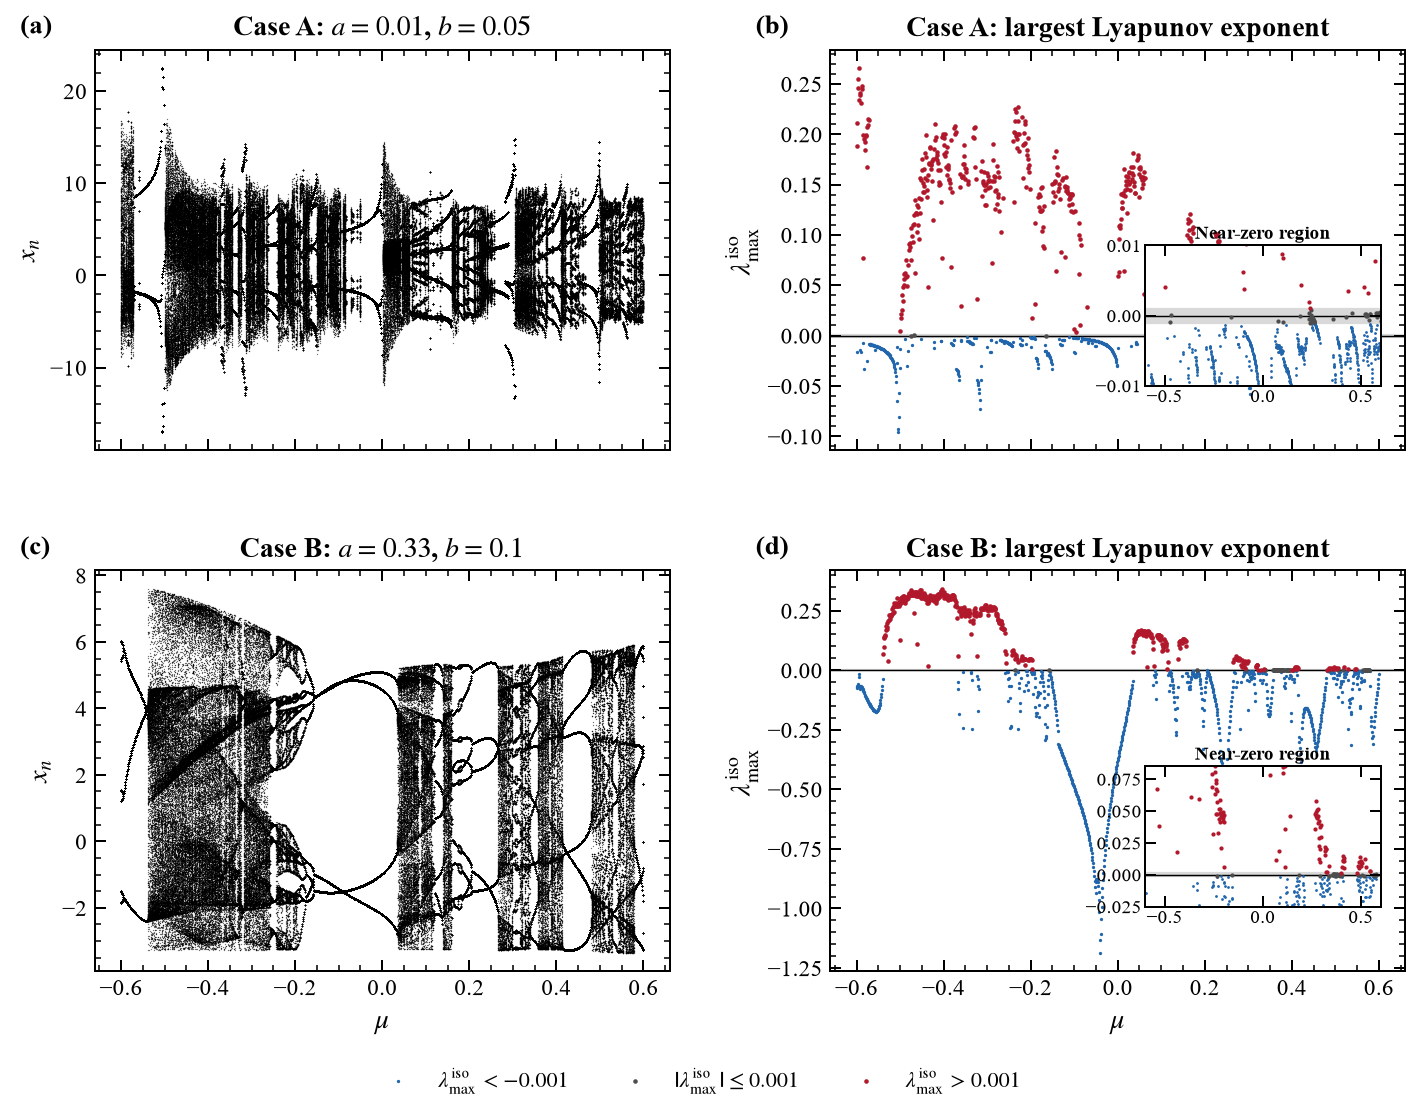

In [5]:
NEGATIVE_COLOR = "#2166ac"
NEUTRAL_COLOR = "#4d4d4d"
POSITIVE_COLOR = "#b2182b"
NEUTRAL_BAND_COLOR = "#d9d9d9"


def plot_lle(axis, mu, values, labels=False, size=2.2):
    finite = np.isfinite(values)
    negative = finite & (values < -LAMBDA_TOL)
    neutral = finite & (np.abs(values) <= LAMBDA_TOL)
    positive = finite & (values > LAMBDA_TOL)

    axis.axhspan(
        -LAMBDA_TOL, LAMBDA_TOL,
        color=NEUTRAL_BAND_COLOR, zorder=0,
    )
    axis.axhline(0.0, color="black", linewidth=0.65, zorder=1)

    axis.scatter(
        mu[negative], values[negative],
        s=size, color=NEGATIVE_COLOR, linewidths=0,
        label=(
            rf"$\lambda_{{\max}}^{{\mathrm{{iso}}}}<-{LAMBDA_TOL:g}$"
            if labels else None
        ),
    )
    axis.scatter(
        mu[neutral], values[neutral],
        s=size+2, color=NEUTRAL_COLOR, linewidths=0,
        label=(
            rf"$|\lambda_{{\max}}^{{\mathrm{{iso}}}}|\leq {LAMBDA_TOL:g}$"
            if labels else None
        ),
    )
    axis.scatter(
        mu[positive], values[positive],
        s=size+2, color=POSITIVE_COLOR, linewidths=0,
        label=(
            rf"$\lambda_{{\max}}^{{\mathrm{{iso}}}}>{LAMBDA_TOL:g}$"
            if labels else None
        ),
    )


def make_main_figure():
    fig, ax = plt.subplots(
        2, 2,
        figsize=(9.2, 7.2),
        sharex="col",
    )

    letters = "abcd"

    for row, case_name in enumerate(("A", "B")):
        result = results[case_name]
        parameters = CASES[case_name]

        ax[row, 0].scatter(
            result["bifurcation_mu"],
            result["bifurcation_x"],
            s=0.35,
            color="black",
            alpha=0.55,
            linewidths=0,
            rasterized=True,
        )
        ax[row, 0].set_ylabel(r"$x_n$")
        ax[row, 0].set_title(
            rf"Case {case_name}: "
            rf"$a={parameters['a']}$, $b={parameters['b']}$"
        )

        plot_lle(
            ax[row, 1],
            result["mu"],
            result["lambda_max"],
            labels=(row == 0),
        )
        ax[row, 1].set_ylabel(r"$\lambda_{\max}^{\mathrm{iso}}$")
        ax[row, 1].set_title(
            f"Case {case_name}: largest Lyapunov exponent"
        )

        inset = inset_axes(
            ax[row, 1],
            width="41%",
            height="35%",
            loc="lower right",
            bbox_to_anchor=(0.0, 0.10, 1.0, 1.0),
            bbox_transform=ax[row, 1].transAxes,
            borderpad=1.1,
        )

        plot_lle(
            inset,
            result["mu"],
            result["lambda_max"],
            labels=False,
            size=1.6,
        )
        inset.set_xlim(MU_MIN, MU_MAX)
        inset.set_ylim(*INSET_YLIM[case_name])
        inset.set_xticks([-0.5, 0.0, 0.5])

        if case_name == "A":
            inset.set_yticks([-0.010, 0.000, 0.010])
        else:
            inset.set_yticks([-0.025, 0.000, 0.025, 0.050, 0.075])

        inset.tick_params(axis="both", labelsize=8.5, pad=1.5)
        inset.set_title("Near-zero region", fontsize=8.5, pad=3)

        for column in (0, 1):
            panel_index = 2*row+column
            ax[row, column].text(
                -0.13,
                1.04,
                f"({letters[panel_index]})",
                transform=ax[row, column].transAxes,
                fontweight="bold",
                fontsize=12,
            )

    ax[1, 0].set_xlabel(r"$\mu$")
    ax[1, 1].set_xlabel(r"$\mu$")

    handles, labels = ax[0, 1].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        frameon=False,
        bbox_to_anchor=(0.5, 0.005),
    )

    fig.subplots_adjust(
        left=0.09,
        right=0.98,
        top=0.93,
        bottom=0.13,
        wspace=0.28,
        hspace=0.30,
    )

    for axis in ax.flat:
        axis.tick_params(which="both", direction="in", top=True, right=True,
                         labelsize=10.5)
        axis.xaxis.label.set_size(12.5)
        axis.yaxis.label.set_size(12.5)
        axis.minorticks_on()

    return fig, ax


fig, ax = make_main_figure()
fig.savefig(
    OUTDIR/"figure_isolated_version2.png",
    dpi=600,
    bbox_inches="tight",
)
fig.savefig(
    OUTDIR/"figure_isolated_version2.pdf",
    bbox_inches="tight",
)
plt.show()

## Verify all initially positive exponents with longer runs

In [8]:
VERIFY_TRANSIENT = 20000
VERIFY_ITERATIONS = 30000


def verify_positive_points(case_name):
    result = results[case_name]
    parameters = CASES[case_name]
    mask = (
        np.isfinite(result["lambda_max"])
        & (result["lambda_max"] > LAMBDA_TOL)
    )

    rows = []
    for mu, initial_value in zip(
        result["mu"][mask],
        result["lambda_max"][mask],
    ):
        verified_value, valid = largest_lyapunov(
            mu,
            parameters["a"],
            parameters["b"],
            n_transient=VERIFY_TRANSIENT,
            n_iter=VERIFY_ITERATIONS,
        )

        if not valid or not np.isfinite(verified_value):
            verified_class = "undefined"
        elif verified_value > LAMBDA_TOL:
            verified_class = "positive"
        elif verified_value < -LAMBDA_TOL:
            verified_class = "negative"
        else:
            verified_class = "near_zero"

        rows.append({
            "case": case_name,
            "mu": mu,
            "initial_lambda": initial_value,
            "verified_lambda": verified_value,
            "verified_class": verified_class,
            "n_transient": VERIFY_TRANSIENT,
            "n_iter": VERIFY_ITERATIONS,
        })

    return pd.DataFrame(rows)


verified_positive = pd.concat(
    [verify_positive_points(name) for name in ("A", "B")],
    ignore_index=True,
)
verified_positive.to_csv(
    OUTDIR/"verified_positive_exponents.csv",
    index=False,
)
display(verified_positive)

,case,mu,initial_lambda,verified_lambda,verified_class,n_transient,n_iter
0,A,-0.600,0.188510,0.203521,positive,20000,30000
1,A,-0.599,0.211105,0.199945,positive,20000,30000
2,A,-0.597,0.254749,0.255376,positive,20000,30000
3,A,-0.596,0.245653,0.251186,positive,20000,30000
4,A,-0.595,0.233494,0.261519,positive,20000,30000
...,...,...,...,...,...,...,...
902,B,0.506,0.009037,0.008153,positive,20000,30000
903,B,0.521,0.012241,0.010852,positive,20000,30000
904,B,0.528,0.005810,0.009583,positive,20000,30000
905,B,0.546,0.003197,0.003011,positive,20000,30000


## Representative phase portraits

Enter parameter values only after examining the corrected Version 2 results and the verified positive-exponent table.

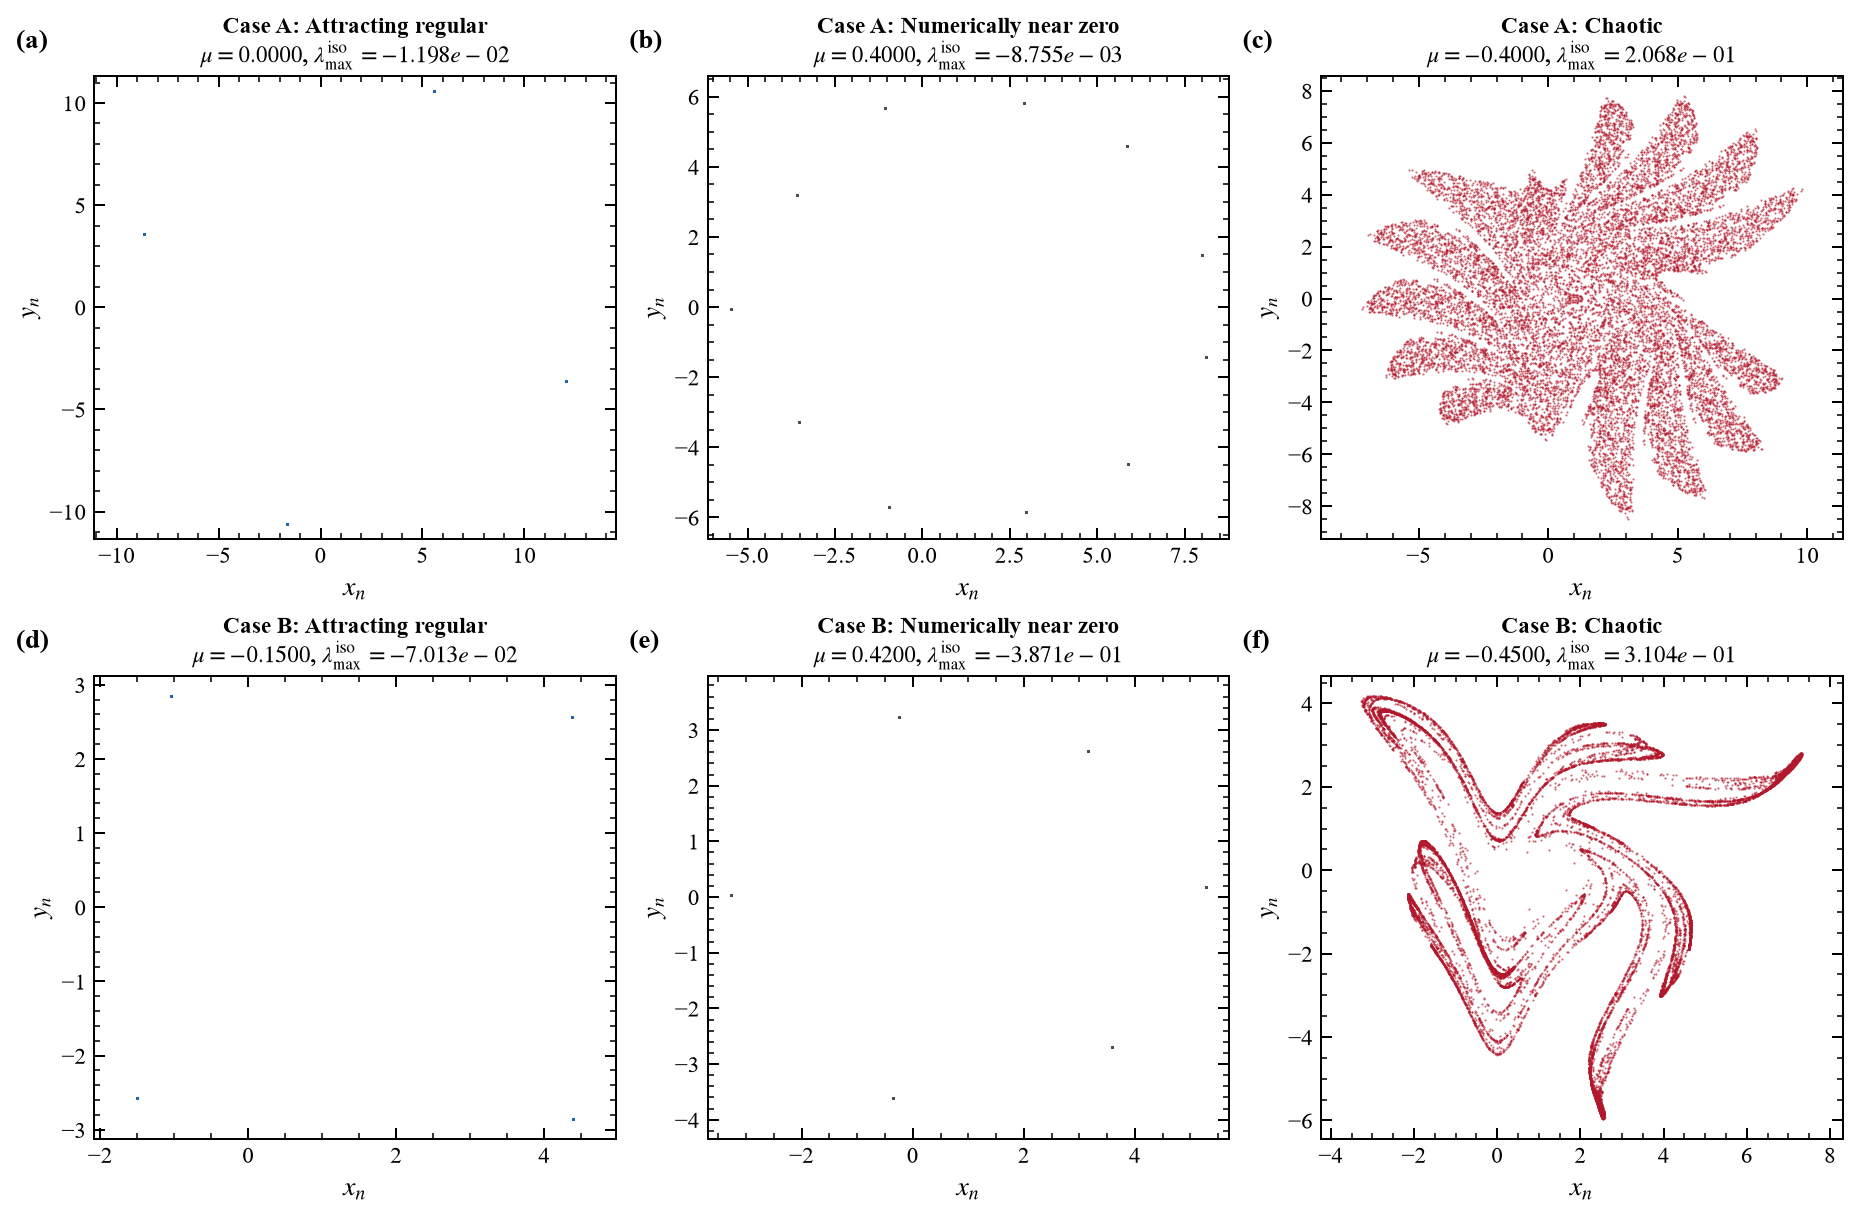

In [6]:
REPRESENTATIVE_MU = {
    "A": {
        "periodic": 0.00,
        "near_zero": 0.40,
        "chaotic": -0.40,
    },
    "B": {
        "periodic": -0.15,
        "near_zero": 0.42,
        "chaotic": -0.45,
    },
}


def make_portrait_figure(
    selection,
    n_transient=30_000,
    n_keep=15_000,
    lyapunov_iterations=20_000,
):
    """
    Plot representative isolated-map attractors in the
    physical phase plane (x_n, y_n).
    """

    regimes = (
        "periodic",
        "near_zero",
        "chaotic",
    )

    regime_titles = {
        "periodic": "Attracting regular",
        "near_zero": "Numerically near zero",
        "chaotic": "Chaotic",
    }

    regime_colors = {
        "periodic": NEGATIVE_COLOR,
        "near_zero": NEUTRAL_COLOR,
        "chaotic": POSITIVE_COLOR,
    }

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(11.5, 7.5),
        constrained_layout=True,
    )

    panel_letters = "abcdef"

    for row, case_name in enumerate(("A", "B")):
        parameters = CASES[case_name]

        for column, regime in enumerate(regimes):
            axis = axes[row, column]
            mu = selection[case_name][regime]

            panel_index = 3 * row + column

            axis.text(
                -0.15,
                1.06,
                f"({panel_letters[panel_index]})",
                transform=axis.transAxes,
                fontweight="bold",
                fontsize=12,
            )

            if mu is None:
                axis.text(
                    0.5,
                    0.5,
                    f"No representative\n{regime} value selected",
                    ha="center",
                    va="center",
                    transform=axis.transAxes,
                )

                axis.set_title(
                    f"Case {case_name}: "
                    f"{regime_titles[regime]}"
                )

                axis.set_xticks([])
                axis.set_yticks([])
                continue

            xs, ys, orbit_valid = compute_orbit(
                mu,
                parameters["a"],
                parameters["b"],
                x0=X0,
                y0=Y0,
                n_transient=n_transient,
                n_keep=n_keep,
            )

            exponent, exponent_valid = largest_lyapunov(
                mu,
                parameters["a"],
                parameters["b"],
                x0=X0,
                y0=Y0,
                n_transient=n_transient,
                n_iter=lyapunov_iterations,
            )

            if orbit_valid:
                axis.scatter(
                    xs,
                    ys,
                    s=0.9,
                    color=regime_colors[regime],
                    alpha=0.65,
                    linewidths=0,
                    rasterized=True,
                )
            else:
                axis.text(
                    0.5,
                    0.5,
                    "Trajectory diverged",
                    ha="center",
                    va="center",
                    transform=axis.transAxes,
                )

            if exponent_valid:
                exponent_text = (
                    rf"$\lambda_{{\max}}^"
                    rf"{{\mathrm{{iso}}}}"
                    rf"={exponent:.3e}$"
                )
            else:
                exponent_text = (
                    r"$\lambda_{\max}^{\mathrm{iso}}$ "
                    "undefined"
                )

            axis.set_title(
                f"Case {case_name}: "
                f"{regime_titles[regime]}\n"
                rf"$\mu={mu:.4f}$, "
                f"{exponent_text}",
                fontsize=10.5,
                pad=6,
            )

            axis.set_xlabel(r"$x_n$")
            axis.set_ylabel(r"$y_n$", fontsize=12)
            axis.tick_params(which="both", direction="in", top=True,
                             right=True, labelsize=10.5)
            axis.minorticks_on()

            axis.set_aspect(
                "equal",
                adjustable="datalim",
            )

    fig.savefig(
        OUTDIR / "representative_phase_portraits.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTDIR / "representative_phase_portraits.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        OUTDIR / "representative_phase_portraits.eps",
        bbox_inches="tight",
    )
    plt.show()

    return fig, axes


fig_portraits, axes_portraits = make_portrait_figure(
    REPRESENTATIVE_MU
)

Automatically verified representative parameters:
Case A: {'periodic': -0.5459999999999999, 'near_zero': 0.245, 'chaotic': 0.32100000000000006}
Case B: {'periodic': -0.11499999999999999, 'near_zero': 0.369, 'chaotic': -0.498}


,case,requested_regime,selected_mu,verified_lambda_max,verified_class,selection_successful
0,A,periodic,-0.546,-0.012184,periodic,True
1,A,near_zero,0.245,-0.000056,near_zero,True
2,A,chaotic,0.321,0.060644,chaotic,True
3,B,periodic,-0.115,-0.415155,periodic,True
4,B,near_zero,0.369,0.000026,near_zero,True
5,B,chaotic,-0.498,0.297433,chaotic,True


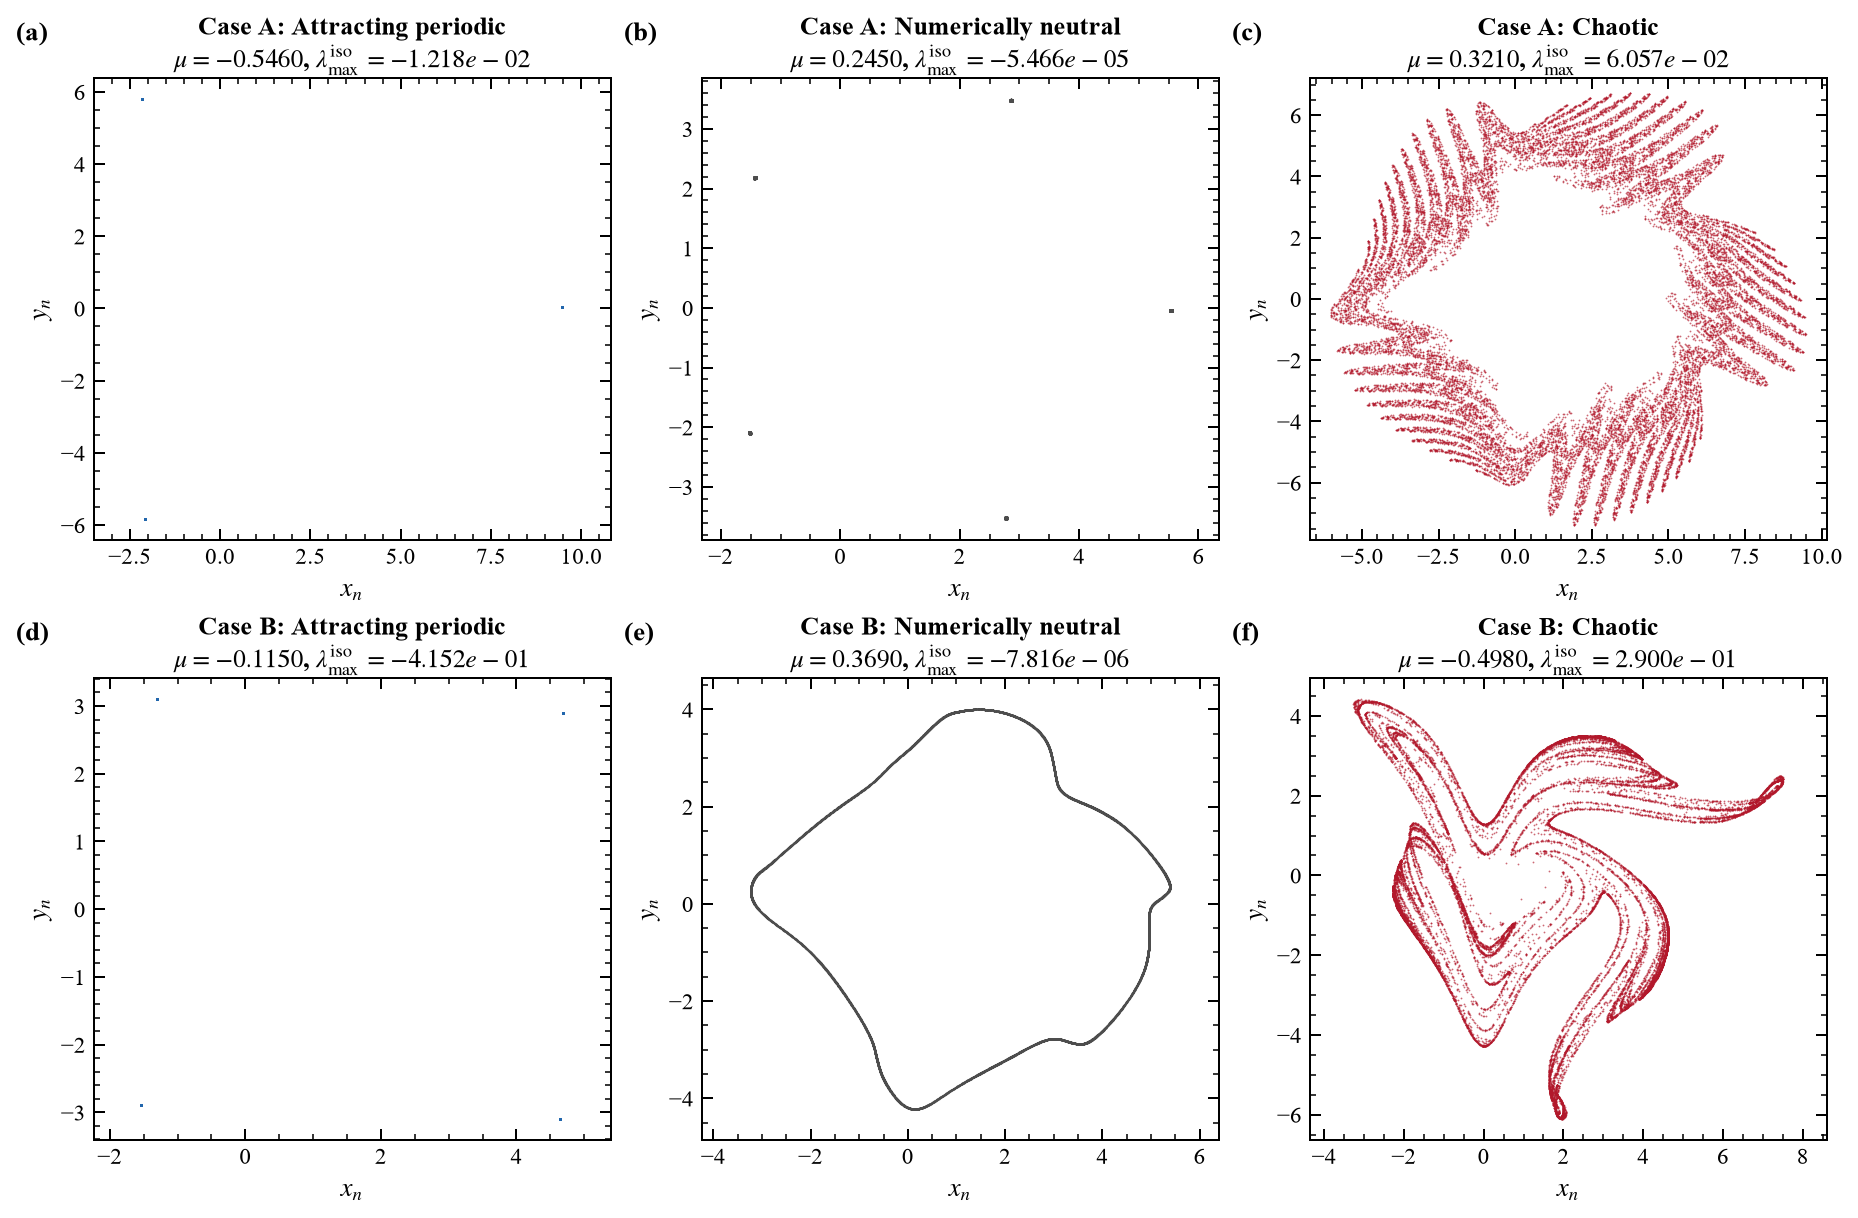

,case,requested_regime,mu,lambda_max,final_regime,distinct_orbit_points,x_range,y_range,path_length,median_step,orbit_valid,agreement
0,A,periodic,-0.546,-0.012176,periodic,3,11.620157,11.618882,250178.462461,12.945788,True,True
1,A,near_zero,0.245,-0.000055,near_zero,20000,7.087658,7.028674,88582.126221,4.441201,True,True
2,A,chaotic,0.321,0.060565,chaotic,20000,15.514641,14.127410,128051.834128,6.392217,True,True
3,B,periodic,-0.115,-0.415160,periodic,4,6.234307,6.191897,120907.216482,5.998624,True,True
4,B,near_zero,0.369,-0.000008,near_zero,20000,8.616941,8.223971,79464.975870,3.898372,True,True
5,B,chaotic,-0.498,0.290029,chaotic,20000,10.773217,10.520649,114946.197975,5.905112,True,True


All representative portraits retained their requested classifications during the final long calculation.


In [7]:
# ============================================================
# AUTOMATIC SELECTION OF REPRESENTATIVE PHASE PORTRAITS
# ============================================================

# Color definitions
NEGATIVE_COLOR = "#2166ac"
NEUTRAL_COLOR = "#4d4d4d"
POSITIVE_COLOR = "#b2182b"

# Candidate-selection settings
SELECTION_TRANSIENT = 20_000
SELECTION_ITERATIONS = 30_000
SELECTION_ORBIT_POINTS = 5_000

# Final portrait settings
PORTRAIT_TRANSIENT = 50_000
PORTRAIT_POINTS = 20_000
PORTRAIT_LYAPUNOV_ITERATIONS = 50_000

# Neutral-orbit geometry settings
DISTINCT_POINT_DECIMALS = 8
MINIMUM_DISTINCT_POINTS_NEUTRAL = 200
MINIMUM_NEUTRAL_X_RANGE = 1.0
MINIMUM_NEUTRAL_Y_RANGE = 1.0


# ============================================================
# 1. CLASSIFY THE LARGEST LYAPUNOV EXPONENT
# ============================================================

def classify_exponent(
    exponent,
    tolerance=LAMBDA_TOL,
):
    """
    Classify a largest Lyapunov exponent.

    Returns
    -------
    str
        'periodic', 'near_zero', 'chaotic', or 'undefined'.
    """

    if not np.isfinite(exponent):
        return "undefined"

    if exponent > tolerance:
        return "chaotic"

    if exponent < -tolerance:
        return "periodic"

    return "near_zero"


# ============================================================
# 2. FIND CONTIGUOUS PARAMETER INTERVALS
# ============================================================

def find_contiguous_blocks(indices):
    """
    Split an integer-index array into contiguous blocks.

    Example
    -------
    [1, 2, 3, 8, 9] becomes:
    [array([1, 2, 3]), array([8, 9])]
    """

    indices = np.asarray(
        indices,
        dtype=int,
    )

    if indices.size == 0:
        return []

    split_positions = (
        np.where(
            np.diff(indices) > 1
        )[0]
        + 1
    )

    return np.split(
        indices,
        split_positions,
    )


def regime_mask(
    exponents,
    requested_regime,
    tolerance=LAMBDA_TOL,
):
    """
    Construct a Boolean mask for a requested dynamical class.
    """

    finite = np.isfinite(exponents)

    if requested_regime == "periodic":
        return (
            finite
            & (exponents < -tolerance)
        )

    if requested_regime == "near_zero":
        return (
            finite
            & (
                np.abs(exponents)
                <= tolerance
            )
        )

    if requested_regime == "chaotic":
        return (
            finite
            & (exponents > tolerance)
        )

    raise ValueError(
        f"Unknown regime: {requested_regime}"
    )


# ============================================================
# 3. ORDER CANDIDATES INSIDE EACH PARAMETER INTERVAL
# ============================================================

def ordered_interior_indices(
    block,
    trim_fraction=0.15,
    maximum_candidates=31,
):
    """
    Return candidate indices from the interior of an interval.

    Points near the edges are avoided because interval edges may
    be close to bifurcation boundaries. Points near the midpoint
    of the interval are tested first.
    """

    block = np.asarray(
        block,
        dtype=int,
    )

    if block.size == 0:
        return np.array(
            [],
            dtype=int,
        )

    trim = int(
        np.floor(
            trim_fraction
            * block.size
        )
    )

    if 2 * trim < block.size:
        interior = block[
            trim:block.size - trim
        ]
    else:
        interior = block

    number_to_test = min(
        maximum_candidates,
        interior.size,
    )

    sampled_positions = np.unique(
        np.linspace(
            0,
            interior.size - 1,
            number_to_test,
            dtype=int,
        )
    )

    midpoint = (
        sampled_positions.size - 1
    ) / 2.0

    ordered_positions = sorted(
        sampled_positions,
        key=lambda position: abs(
            position - midpoint
        ),
    )

    return interior[
        ordered_positions
    ]


# ============================================================
# 4. ORBIT-GEOMETRY DIAGNOSTICS
# ============================================================

def orbit_geometry_metrics(
    xs,
    ys,
    decimals=DISTINCT_POINT_DECIMALS,
):
    """
    Calculate numerical and geometric orbit diagnostics.

    Returns
    -------
    dict
        Number of distinct points, coordinate ranges,
        total path length, and median step length.
    """

    if xs is None or ys is None:
        return {
            "distinct_points": 0,
            "x_range": 0.0,
            "y_range": 0.0,
            "path_length": 0.0,
            "median_step": 0.0,
        }

    xs = np.asarray(xs)
    ys = np.asarray(ys)

    points = np.column_stack(
        (xs, ys)
    )

    rounded_points = np.round(
        points,
        decimals=decimals,
    )

    distinct_points = len(
        np.unique(
            rounded_points,
            axis=0,
        )
    )

    x_range = float(
        np.ptp(xs)
    )

    y_range = float(
        np.ptp(ys)
    )

    if len(xs) > 1:
        step_lengths = np.sqrt(
            np.diff(xs) ** 2
            + np.diff(ys) ** 2
        )

        path_length = float(
            np.sum(step_lengths)
        )

        median_step = float(
            np.median(step_lengths)
        )
    else:
        path_length = 0.0
        median_step = 0.0

    return {
        "distinct_points": distinct_points,
        "x_range": x_range,
        "y_range": y_range,
        "path_length": path_length,
        "median_step": median_step,
    }


# ============================================================
# 5. VERIFY ONE CANDIDATE PARAMETER VALUE
# ============================================================

def verify_candidate(
    case_name,
    requested_regime,
    mu,
    scan_exponent,
    block_left,
    block_right,
    block_points,
):
    """
    Verify one candidate using a longer Lyapunov calculation
    and post-transient orbit-geometry analysis.
    """

    parameters = CASES[case_name]

    verified_exponent, exponent_valid = (
        largest_lyapunov(
            mu,
            parameters["a"],
            parameters["b"],
            x0=X0,
            y0=Y0,
            n_transient=SELECTION_TRANSIENT,
            n_iter=SELECTION_ITERATIONS,
        )
    )

    if exponent_valid:
        verified_class = classify_exponent(
            verified_exponent,
            tolerance=LAMBDA_TOL,
        )
    else:
        verified_class = "undefined"

    xs, ys, orbit_valid = compute_orbit(
        mu,
        parameters["a"],
        parameters["b"],
        x0=X0,
        y0=Y0,
        n_transient=SELECTION_TRANSIENT,
        n_keep=SELECTION_ORBIT_POINTS,
    )

    if orbit_valid:
        geometry = orbit_geometry_metrics(
            xs,
            ys,
        )
    else:
        geometry = {
            "distinct_points": 0,
            "x_range": 0.0,
            "y_range": 0.0,
            "path_length": 0.0,
            "median_step": 0.0,
        }

    # Base acceptance condition
    accepted = (
        verified_class
        == requested_regime
    )

    # Neutral states must also have substantial orbit coverage.
    # This reduces the chance of selecting a low-period orbit
    # merely because its finite-time exponent is close to zero.
    if requested_regime == "near_zero":
        accepted = (
            verified_class == "near_zero"
            and geometry["distinct_points"]
            >= MINIMUM_DISTINCT_POINTS_NEUTRAL
            and geometry["x_range"]
            >= MINIMUM_NEUTRAL_X_RANGE
            and geometry["y_range"]
            >= MINIMUM_NEUTRAL_Y_RANGE
        )

    return {
        "case": case_name,
        "requested_regime": requested_regime,
        "mu": mu,
        "scan_lambda": scan_exponent,
        "verified_lambda": verified_exponent,
        "verified_class": verified_class,
        "exponent_valid": exponent_valid,
        "orbit_valid": orbit_valid,
        "distinct_orbit_points": geometry[
            "distinct_points"
        ],
        "x_range": geometry["x_range"],
        "y_range": geometry["y_range"],
        "path_length": geometry[
            "path_length"
        ],
        "median_step": geometry[
            "median_step"
        ],
        "block_left": block_left,
        "block_right": block_right,
        "block_points": block_points,
        "accepted": accepted,
    }


# ============================================================
# 6. SELECT ONE VERIFIED REPRESENTATIVE PER CLASS
# ============================================================

def find_verified_representative(
    case_name,
    requested_regime,
    result,
    minimum_block_points=5,
    trim_fraction=0.15,
    maximum_candidates_per_block=31,
):
    """
    Find one verified representative parameter value.

    Long contiguous intervals are searched first. Candidate
    points near the middle of each interval are tested before
    points closer to the interval boundaries.
    """

    mu_values = result["mu"]
    scan_exponents = result[
        "lambda_max"
    ]

    mask = regime_mask(
        scan_exponents,
        requested_regime,
    )

    blocks = find_contiguous_blocks(
        np.where(mask)[0]
    )

    acceptable_blocks = [
        block
        for block in blocks
        if block.size
        >= minimum_block_points
    ]

    # Search larger parameter intervals first.
    acceptable_blocks = sorted(
        acceptable_blocks,
        key=len,
        reverse=True,
    )

    attempt_records = []

    for block in acceptable_blocks:
        candidate_indices = (
            ordered_interior_indices(
                block,
                trim_fraction=trim_fraction,
                maximum_candidates=(
                    maximum_candidates_per_block
                ),
            )
        )

        block_left = float(
            mu_values[block[0]]
        )

        block_right = float(
            mu_values[block[-1]]
        )

        for index in candidate_indices:
            candidate_mu = float(
                mu_values[index]
            )

            candidate_result = (
                verify_candidate(
                    case_name=case_name,
                    requested_regime=(
                        requested_regime
                    ),
                    mu=candidate_mu,
                    scan_exponent=(
                        scan_exponents[index]
                    ),
                    block_left=block_left,
                    block_right=block_right,
                    block_points=block.size,
                )
            )

            attempt_records.append(
                candidate_result
            )

            if candidate_result[
                "accepted"
            ]:
                return (
                    candidate_mu,
                    candidate_result[
                        "verified_lambda"
                    ],
                    pd.DataFrame(
                        attempt_records
                    ),
                )

    return (
        None,
        np.nan,
        pd.DataFrame(
            attempt_records
        ),
    )


# ============================================================
# 7. AUTOMATIC SELECTION FOR CASES A AND B
# ============================================================

VERIFIED_REPRESENTATIVE_MU = {
    "A": {},
    "B": {},
}

selection_summary_records = []
selection_attempt_frames = []

for case_name in ("A", "B"):
    for requested_regime in (
        "periodic",
        "near_zero",
        "chaotic",
    ):
        (
            selected_mu,
            verified_exponent,
            attempt_table,
        ) = find_verified_representative(
            case_name,
            requested_regime,
            results[case_name],
        )

        VERIFIED_REPRESENTATIVE_MU[
            case_name
        ][requested_regime] = (
            selected_mu
        )

        if selected_mu is None:
            verified_class = (
                "not_selected"
            )
        else:
            verified_class = (
                classify_exponent(
                    verified_exponent,
                    tolerance=LAMBDA_TOL,
                )
            )

        selection_summary_records.append(
            {
                "case": case_name,
                "requested_regime": (
                    requested_regime
                ),
                "selected_mu": (
                    selected_mu
                ),
                "verified_lambda_max": (
                    verified_exponent
                ),
                "verified_class": (
                    verified_class
                ),
                "selection_successful": (
                    selected_mu is not None
                ),
            }
        )

        if not attempt_table.empty:
            selection_attempt_frames.append(
                attempt_table
            )


selection_summary = pd.DataFrame(
    selection_summary_records
)

print(
    "Automatically verified "
    "representative parameters:"
)

for case_name in ("A", "B"):
    print(
        f"Case {case_name}: "
        f"{VERIFIED_REPRESENTATIVE_MU[case_name]}"
    )

display(
    selection_summary
)

selection_summary.to_csv(
    OUTDIR
    / "verified_representative_parameters.csv",
    index=False,
)

if selection_attempt_frames:
    selection_attempts = pd.concat(
        selection_attempt_frames,
        ignore_index=True,
    )

    selection_attempts.to_csv(
        OUTDIR
        / "representative_selection_attempts.csv",
        index=False,
    )


# ============================================================
# 8. CREATE THE FINAL SIX-PANEL PORTRAIT FIGURE
# ============================================================

def make_automatic_portrait_figure(
    selection,
    n_transient=PORTRAIT_TRANSIENT,
    n_keep=PORTRAIT_POINTS,
    lyapunov_iterations=(
        PORTRAIT_LYAPUNOV_ITERATIONS
    ),
):
    """
    Plot automatically selected representative phase portraits.

    Rows
    ----
    Case A and Case B.

    Columns
    -------
    Attracting periodic, numerically neutral, and chaotic.

    Returns
    -------
    fig
        Matplotlib figure.

    axes
        Two-dimensional subplot array.

    portrait_summary
        DataFrame containing the final numerical checks.
    """

    regimes = (
        "periodic",
        "near_zero",
        "chaotic",
    )

    regime_titles = {
        "periodic": "Attracting periodic",
        "near_zero": "Numerically neutral",
        "chaotic": "Chaotic",
    }

    regime_colors = {
        "periodic": NEGATIVE_COLOR,
        "near_zero": NEUTRAL_COLOR,
        "chaotic": POSITIVE_COLOR,
    }

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(11.5, 7.5),
        constrained_layout=True,
    )

    panel_letters = "abcdef"
    portrait_records = []

    for row, case_name in enumerate(
        ("A", "B")
    ):
        parameters = CASES[case_name]

        for column, requested_regime in enumerate(
            regimes
        ):
            axis = axes[row, column]

            panel_index = (
                3 * row + column
            )

            axis.text(
                -0.15,
                1.07,
                f"({panel_letters[panel_index]})",
                transform=axis.transAxes,
                fontsize=12,
                fontweight="bold",
                va="bottom",
            )

            mu = selection[
                case_name
            ][requested_regime]

            # If automatic selection did not find a qualifying
            # candidate, leave an explicitly labelled blank panel.
            if (
                mu is None
                or not np.isfinite(mu)
            ):
                axis.text(
                    0.5,
                    0.5,
                    "No robust parameter interval\n"
                    "found automatically",
                    ha="center",
                    va="center",
                    transform=axis.transAxes,
                )

                axis.set_title(
                    f"Case {case_name}: "
                    f"{regime_titles[requested_regime]}"
                )

                axis.set_xticks([])
                axis.set_yticks([])

                portrait_records.append(
                    {
                        "case": case_name,
                        "requested_regime": (
                            requested_regime
                        ),
                        "mu": np.nan,
                        "lambda_max": np.nan,
                        "final_regime": (
                            "not_selected"
                        ),
                        "distinct_orbit_points": 0,
                        "x_range": 0.0,
                        "y_range": 0.0,
                        "orbit_valid": False,
                        "agreement": False,
                    }
                )

                continue

            # Final long orbit calculation
            xs, ys, orbit_valid = (
                compute_orbit(
                    mu,
                    parameters["a"],
                    parameters["b"],
                    x0=X0,
                    y0=Y0,
                    n_transient=n_transient,
                    n_keep=n_keep,
                )
            )

            # Final long Lyapunov calculation
            exponent, exponent_valid = (
                largest_lyapunov(
                    mu,
                    parameters["a"],
                    parameters["b"],
                    x0=X0,
                    y0=Y0,
                    n_transient=n_transient,
                    n_iter=(
                        lyapunov_iterations
                    ),
                )
            )

            if (
                exponent_valid
                and np.isfinite(exponent)
            ):
                final_regime = (
                    classify_exponent(
                        exponent,
                        tolerance=LAMBDA_TOL,
                    )
                )
            else:
                final_regime = (
                    "undefined"
                )

            if orbit_valid:
                geometry = (
                    orbit_geometry_metrics(
                        xs,
                        ys,
                    )
                )
            else:
                geometry = {
                    "distinct_points": 0,
                    "x_range": 0.0,
                    "y_range": 0.0,
                    "path_length": 0.0,
                    "median_step": 0.0,
                }

            agreement = (
                final_regime
                == requested_regime
            )

            if requested_regime == "near_zero":
                agreement = (
                    agreement
                    and geometry[
                        "distinct_points"
                    ]
                    >= MINIMUM_DISTINCT_POINTS_NEUTRAL
                    and geometry["x_range"]
                    >= MINIMUM_NEUTRAL_X_RANGE
                    and geometry["y_range"]
                    >= MINIMUM_NEUTRAL_Y_RANGE
                )

            portrait_records.append(
                {
                    "case": case_name,
                    "requested_regime": (
                        requested_regime
                    ),
                    "mu": mu,
                    "lambda_max": exponent,
                    "final_regime": (
                        final_regime
                    ),
                    "distinct_orbit_points": (
                        geometry[
                            "distinct_points"
                        ]
                    ),
                    "x_range": geometry[
                        "x_range"
                    ],
                    "y_range": geometry[
                        "y_range"
                    ],
                    "path_length": geometry[
                        "path_length"
                    ],
                    "median_step": geometry[
                        "median_step"
                    ],
                    "orbit_valid": orbit_valid,
                    "agreement": agreement,
                }
            )

            if orbit_valid:
                axis.scatter(
                    xs,
                    ys,
                    s=0.65,
                    color=regime_colors[
                        requested_regime
                    ],
                    alpha=0.65,
                    linewidths=0,
                    rasterized=True,
                )
            else:
                axis.text(
                    0.5,
                    0.5,
                    "Trajectory diverged",
                    ha="center",
                    va="center",
                    transform=axis.transAxes,
                )

            if (
                exponent_valid
                and np.isfinite(exponent)
            ):
                exponent_text = (
                    rf"$\lambda_{{\max}}^"
                    rf"{{\mathrm{{iso}}}}"
                    rf"={exponent:.3e}$"
                )
            else:
                exponent_text = (
                    r"$\lambda_{\max}^{\mathrm{iso}}$ "
                    "undefined"
                )

            if agreement:
                review_text = ""
            else:
                review_text = (
                    "\n[classification requires review]"
                )

            axis.set_title(
                f"Case {case_name}: "
                f"{regime_titles[requested_regime]}"
                "\n"
                rf"$\mu={mu:.4f}$, "
                f"{exponent_text}"
                f"{review_text}",
                fontsize=11.5,
                pad=5,
            )

            axis.set_xlabel(r"$x_n$", fontsize=12)
            axis.set_ylabel(r"$y_n$", fontsize=12)
            axis.tick_params(which="both", direction="in", top=True,
                             right=True, labelsize=10.5)
            axis.minorticks_on()
            # Preserve the attractor's phase-space geometry.
            axis.set_aspect(
                "equal",
                adjustable="datalim",
            )

    portrait_summary = pd.DataFrame(
        portrait_records
    )

    fig.savefig(
        OUTDIR
        / "automatic_representative_phase_portraits.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTDIR
        / "automatic_representative_phase_portraits.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        OUTDIR
        / "automatic_representative_phase_portraits.eps",
        bbox_inches="tight",
    )

    portrait_summary.to_csv(
        OUTDIR
        / "automatic_portrait_classification_summary.csv",
        index=False,
    )

    plt.show()

    return (
        fig,
        axes,
        portrait_summary,
    )


# ============================================================
# 9. GENERATE THE FIGURE
# ============================================================

(
    fig_portraits,
    axes_portraits,
    portrait_summary,
) = make_automatic_portrait_figure(
    VERIFIED_REPRESENTATIVE_MU
)

display(
    portrait_summary
)


# ============================================================
# 10. FINAL CONSISTENCY CHECK
# ============================================================

selected_portraits = (
    portrait_summary.loc[
        portrait_summary[
            "final_regime"
        ]
        != "not_selected"
    ]
)

if selected_portraits.empty:
    print(
        "No representative portraits were selected."
    )

elif selected_portraits[
    "agreement"
].all():
    print(
        "All representative portraits retained "
        "their requested classifications during "
        "the final long calculation."
    )

else:
    print(
        "Warning: at least one representative "
        "portrait requires review."
    )

    display(
        selected_portraits.loc[
            ~selected_portraits[
                "agreement"
            ]
        ]
    )

## Multiple-initial-condition test for multistability

Replace the rectangle with the initialization rectangle used in the network study. Add parameter values near abrupt branch changes, positive-exponent intervals, and edges of periodic windows.  

## Multistability plots: Lyapunov exponent and orbit mean

The orbit mean can reveal geometrically distinct or symmetry-related attractors that have similar Lyapunov exponents.

In [8]:
# ============================================================
# 1. IMPORTS AND SETTINGS
# ============================================================

from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist


REQUIRED_OBJECTS = [
    "CASES",
    "compute_orbit",
    "largest_lyapunov",
    "classify_exponent",
    "LAMBDA_TOL",
    "OUTDIR",
]

missing_objects = [name for name in REQUIRED_OBJECTS if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Run the existing isolated-map analysis first. Missing: "
        + ", ".join(missing_objects)
    )

OUTDIR = Path(OUTDIR)
OUTDIR.mkdir(parents=True, exist_ok=True)
MULTISTABILITY_OUTDIR = OUTDIR / "isolated_multistability_comment4"
MULTISTABILITY_OUTDIR.mkdir(parents=True, exist_ok=True)

INITIAL_CONDITION_RECTANGLE = {
    "x": (-1.0, 1.0),
    "y": (-1.0, 1.0),
}

N_INITIAL_CONDITIONS = 100
MULTISTABILITY_TRANSIENT = 20_000
MULTISTABILITY_LYAPUNOV_ITERATIONS = 10_000
MULTISTABILITY_ORBIT_POINTS = 2_000
MULTISTABILITY_SEED = 20260903

# A class or attractor group must contain at least this many sampled
# initial conditions before it is reported as robust coexistence.
MINIMUM_GROUP_COUNT = 2

# Low-period detection. A zero return value means that no period up to
# MAXIMUM_TEST_PERIOD was detected under PERIOD_TOLERANCE.
MAXIMUM_TEST_PERIOD = 128
PERIOD_TOLERANCE = 1.0e-6
PERIOD_TEST_POINTS = 1_000

# Phase-insensitive signature quantiles.
SIGNATURE_QUANTILES = np.linspace(0.05, 0.95, 19)

# Hierarchical grouping threshold after robust standardization of the
# attractor signatures. Candidate groups are verified visually later.
ATTRACTOR_GROUP_DISTANCE = 2.5

# Target dynamically relevant regions. Automatically verified periodic,
# neutral, and chaotic values are added if available.
MU_TEST_BASE = {
    "A": [-0.55, -0.50, -0.40, -0.10, 0.10, 0.24, 0.30, 0.32, 0.40, 0.48],
    "B": [-0.58, -0.50, -0.45, -0.20, -0.10, -0.06, 0.05, 0.15, 0.30, 0.37, 0.43],
}

# Colors may already exist in the main notebook. These fallbacks preserve
# execution if their names differ there.
NEGATIVE_PLOT_COLOR = globals().get("NEGATIVE_COLOR", globals().get("PERIODIC_COLOR", "#2166AC"))
NEUTRAL_PLOT_COLOR = globals().get("NEUTRAL_COLOR", "#4D4D4D")
POSITIVE_PLOT_COLOR = globals().get("POSITIVE_COLOR", globals().get("CHAOTIC_COLOR", "#B2182B"))

print("Comment 4 output directory:", MULTISTABILITY_OUTDIR.resolve())


Comment 4 output directory: C:\Users\em18702\OneDrive - AUT University\GMAP\gm_version2_outputs\isolated_multistability_comment4


In [9]:
# ============================================================
# 2. PARAMETER VALUES AND NUMERICAL HELPERS
# ============================================================

def build_mu_test_values(base_values, representative_values=None, decimals=6):
    combined = {"A": list(base_values["A"]), "B": list(base_values["B"])}
    if representative_values is not None:
        for case_name in ("A", "B"):
            for regime in ("periodic", "near_zero", "chaotic"):
                mu = representative_values.get(case_name, {}).get(regime)
                if mu is not None and np.isfinite(mu):
                    combined[case_name].append(float(mu))
    for case_name in ("A", "B"):
        combined[case_name] = sorted({
            round(float(mu), decimals) for mu in combined[case_name]
        })
    return combined


MU_TEST = build_mu_test_values(
    MU_TEST_BASE,
    globals().get("VERIFIED_REPRESENTATIVE_MU"),
)

print("Targeted mu values:")
for case_name in ("A", "B"):
    print(f"  Case {case_name}: {MU_TEST[case_name]}")


def estimate_period(xs, ys, maximum_period=MAXIMUM_TEST_PERIOD,
                    tolerance=PERIOD_TOLERANCE,
                    test_points=PERIOD_TEST_POINTS):
    """Estimate a low period from the final portion of one orbit."""
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    points = min(test_points, len(xs))
    xs = xs[-points:]
    ys = ys[-points:]
    maximum_available = min(maximum_period, len(xs) // 4)
    for period in range(1, maximum_available + 1):
        distances = np.hypot(xs[period:] - xs[:-period], ys[period:] - ys[:-period])
        if distances.size and float(np.max(distances)) <= tolerance:
            return period
    return 0


def orbit_signature(xs, ys):
    """Create a phase-insensitive attractor signature."""
    xs = np.asarray(xs, dtype=float)
    ys = np.asarray(ys, dtype=float)
    dx = np.diff(xs)
    dy = np.diff(ys)
    steps = np.hypot(dx, dy)
    return {
        "mean_x": float(np.mean(xs)),
        "mean_y": float(np.mean(ys)),
        "std_x": float(np.std(xs)),
        "std_y": float(np.std(ys)),
        "x_min": float(np.min(xs)),
        "x_max": float(np.max(xs)),
        "y_min": float(np.min(ys)),
        "y_max": float(np.max(ys)),
        "x_range": float(np.ptp(xs)),
        "y_range": float(np.ptp(ys)),
        "path_length": float(np.sum(steps)),
        "median_step": float(np.median(steps)) if steps.size else 0.0,
        "x_quantiles": np.quantile(xs, SIGNATURE_QUANTILES),
        "y_quantiles": np.quantile(ys, SIGNATURE_QUANTILES),
    }


Targeted mu values:
  Case A: [-0.55, -0.546, -0.5, -0.4, -0.1, 0.1, 0.24, 0.245, 0.3, 0.32, 0.321, 0.4, 0.48]
  Case B: [-0.58, -0.5, -0.498, -0.45, -0.2, -0.115, -0.1, -0.06, 0.05, 0.15, 0.3, 0.369, 0.37, 0.43]


In [10]:
# ============================================================
# 3. MULTIPLE-INITIAL-CONDITION CALCULATION
# ============================================================

def multistability_test(
    case_name,
    mu_values,
    n_initial_conditions=N_INITIAL_CONDITIONS,
    rectangle=INITIAL_CONDITION_RECTANGLE,
    n_transient=MULTISTABILITY_TRANSIENT,
    n_lyapunov=MULTISTABILITY_LYAPUNOV_ITERATIONS,
    n_orbit_points=MULTISTABILITY_ORBIT_POINTS,
    seed=MULTISTABILITY_SEED,
):
    parameters = CASES[case_name]
    case_offset = 0 if case_name == "A" else 100_000_000
    rows = []
    orbit_store = {}

    for mu_index, mu in enumerate(mu_values):
        print(f"Case {case_name}, mu={mu:.6f}")
        for initial_condition_id in range(n_initial_conditions):
            # A realization-specific generator makes every row independently
            # reproducible even if the loop order is changed later.
            realization_seed = (
                seed + case_offset + mu_index * 10_000 + initial_condition_id
            )
            rng = np.random.default_rng(realization_seed)
            x0 = float(rng.uniform(*rectangle["x"]))
            y0 = float(rng.uniform(*rectangle["y"]))

            exponent, exponent_valid = largest_lyapunov(
                mu,
                parameters["a"],
                parameters["b"],
                x0=x0,
                y0=y0,
                n_transient=n_transient,
                n_iter=n_lyapunov,
            )
            xs, ys, orbit_valid = compute_orbit(
                mu,
                parameters["a"],
                parameters["b"],
                x0=x0,
                y0=y0,
                n_transient=n_transient,
                n_keep=n_orbit_points,
            )

            exponent_valid = bool(exponent_valid and np.isfinite(exponent))
            orbit_valid = bool(
                orbit_valid
                and len(xs) == n_orbit_points
                and len(ys) == n_orbit_points
                and np.all(np.isfinite(xs))
                and np.all(np.isfinite(ys))
            )
            valid = bool(exponent_valid and orbit_valid)

            if exponent_valid:
                dynamical_class = classify_exponent(exponent, tolerance=LAMBDA_TOL)
            else:
                dynamical_class = "undefined"

            if orbit_valid:
                sig = orbit_signature(xs, ys)
                detected_period = estimate_period(xs, ys)
                orbit_store[(case_name, float(mu), initial_condition_id)] = (
                    np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
                )
            else:
                sig = {
                    "mean_x": np.nan, "mean_y": np.nan,
                    "std_x": np.nan, "std_y": np.nan,
                    "x_min": np.nan, "x_max": np.nan,
                    "y_min": np.nan, "y_max": np.nan,
                    "x_range": np.nan, "y_range": np.nan,
                    "path_length": np.nan, "median_step": np.nan,
                    "x_quantiles": np.full(len(SIGNATURE_QUANTILES), np.nan),
                    "y_quantiles": np.full(len(SIGNATURE_QUANTILES), np.nan),
                }
                detected_period = 0

            row = {
                "case": case_name,
                "mu": float(mu),
                "initial_condition_id": initial_condition_id,
                "seed": realization_seed,
                "x0": x0,
                "y0": y0,
                "lambda_max": float(exponent) if exponent_valid else np.nan,
                "dynamical_class": dynamical_class,
                "detected_period": int(detected_period),
                "exponent_valid": exponent_valid,
                "orbit_valid": orbit_valid,
                "valid": valid,
            }
            for name in [
                "mean_x", "mean_y", "std_x", "std_y", "x_min", "x_max",
                "y_min", "y_max", "x_range", "y_range", "path_length",
                "median_step",
            ]:
                row[name] = sig[name]
            for index, value in enumerate(sig["x_quantiles"]):
                row[f"xq_{index:02d}"] = float(value)
            for index, value in enumerate(sig["y_quantiles"]):
                row[f"yq_{index:02d}"] = float(value)
            rows.append(row)

    return pd.DataFrame(rows), orbit_store


start_time = perf_counter()
frames = []
MULTISTABILITY_ORBITS = {}

for case_name in ("A", "B"):
    frame, stored_orbits = multistability_test(case_name, MU_TEST[case_name])
    frames.append(frame)
    MULTISTABILITY_ORBITS.update(stored_orbits)

multistability_results = pd.concat(frames, ignore_index=True)
multistability_results.to_csv(
    MULTISTABILITY_OUTDIR / "multistability_initial_conditions.csv",
    index=False,
)
print(f"Completed in {perf_counter() - start_time:.1f} seconds.")
print("Realizations:", len(multistability_results))


Case A, mu=-0.550000
Case A, mu=-0.546000
Case A, mu=-0.500000
Case A, mu=-0.400000
Case A, mu=-0.100000
Case A, mu=0.100000
Case A, mu=0.240000
Case A, mu=0.245000
Case A, mu=0.300000
Case A, mu=0.320000
Case A, mu=0.321000
Case A, mu=0.400000
Case A, mu=0.480000
Case B, mu=-0.580000
Case B, mu=-0.500000
Case B, mu=-0.498000
Case B, mu=-0.450000
Case B, mu=-0.200000
Case B, mu=-0.115000
Case B, mu=-0.100000
Case B, mu=-0.060000
Case B, mu=0.050000
Case B, mu=0.150000
Case B, mu=0.300000
Case B, mu=0.369000
Case B, mu=0.370000
Case B, mu=0.430000
Completed in 2444.7 seconds.
Realizations: 2700


In [11]:
# ============================================================
# 4. VALID TEMPORAL-CLASS COEXISTENCE
# ============================================================

valid_results = multistability_results.loc[
    multistability_results["valid"]
    & (multistability_results["dynamical_class"] != "undefined")
].copy()

class_counts = (
    valid_results
    .groupby(["case", "mu", "dynamical_class"], as_index=False)
    .size()
    .rename(columns={"size": "count"})
)
class_counts["total_valid"] = class_counts.groupby(
    ["case", "mu"]
)["count"].transform("sum")
class_counts["fraction"] = class_counts["count"] / class_counts["total_valid"]
class_counts["robust_class"] = class_counts["count"] >= MINIMUM_GROUP_COUNT
class_counts.to_csv(
    MULTISTABILITY_OUTDIR / "temporal_class_counts.csv", index=False
)

robust_class_counts = class_counts.loc[class_counts["robust_class"]].copy()
class_coexistence = (
    robust_class_counts
    .groupby(["case", "mu"], as_index=False)
    .agg(
        number_of_robust_classes=("dynamical_class", "nunique"),
        observed_classes=(
            "dynamical_class",
            lambda values: ", ".join(sorted(set(values))),
        ),
        smallest_class_fraction=("fraction", "min"),
        largest_class_fraction=("fraction", "max"),
    )
)
class_coexistence["robust_temporal_coexistence"] = (
    class_coexistence["number_of_robust_classes"] > 1
)
class_coexistence.to_csv(
    MULTISTABILITY_OUTDIR / "temporal_class_coexistence.csv", index=False
)

display(class_counts)
display(class_coexistence.loc[class_coexistence["robust_temporal_coexistence"]])


,case,mu,dynamical_class,count,total_valid,fraction,robust_class
0,A,-0.550,periodic,100,100,1.0,True
1,A,-0.546,periodic,100,100,1.0,True
2,A,-0.500,periodic,100,100,1.0,True
3,A,-0.400,chaotic,100,100,1.0,True
4,A,-0.100,periodic,100,100,1.0,True
5,A,0.100,periodic,100,100,1.0,True
6,A,0.240,chaotic,10,100,0.1,True
7,A,0.240,near_zero,80,100,0.8,True
8,A,0.240,periodic,10,100,0.1,True
9,A,0.245,near_zero,100,100,1.0,True


,case,mu,number_of_robust_classes,observed_classes,smallest_class_fraction,largest_class_fraction,robust_temporal_coexistence
6,A,0.24,3,"chaotic, near_zero, periodic",0.1,0.8,True


In [12]:
# ============================================================
# 5. SAME-CLASS ATTRACTOR GROUPING
# ============================================================

QUANTILE_COLUMNS = [
    *(f"xq_{index:02d}" for index in range(len(SIGNATURE_QUANTILES))),
    *(f"yq_{index:02d}" for index in range(len(SIGNATURE_QUANTILES))),
]
BASE_SIGNATURE_COLUMNS = [
    "lambda_max", "mean_x", "mean_y", "std_x", "std_y",
    "x_range", "y_range", "median_step",
]
SIGNATURE_COLUMNS = BASE_SIGNATURE_COLUMNS + QUANTILE_COLUMNS


def robust_standardize(matrix):
    """Median/MAD scaling with a standard-deviation fallback."""
    center = np.median(matrix, axis=0)
    scale = np.median(np.abs(matrix - center), axis=0)
    standard_deviation = np.std(matrix, axis=0)
    scale = np.where(scale > 1.0e-10, scale, standard_deviation)
    scale = np.where(scale > 1.0e-10, scale, 1.0)
    return (matrix - center) / scale


def assign_same_class_groups(group, distance_threshold=ATTRACTOR_GROUP_DISTANCE):
    """Group geometric signatures within one case, mu, class, and period."""
    group = group.copy()
    group["attractor_group"] = 0
    if len(group) == 1:
        group["attractor_group"] = 1
        return group

    matrix = group[SIGNATURE_COLUMNS].to_numpy(dtype=float)
    finite_rows = np.all(np.isfinite(matrix), axis=1)
    finite_count = int(np.count_nonzero(finite_rows))
    if finite_count == 0:
        return group
    if finite_count == 1:
        group.loc[group.index[finite_rows], "attractor_group"] = 1
        return group

    standardized = robust_standardize(matrix[finite_rows])
    distances = pdist(standardized, metric="euclidean")
    if distances.size == 0 or np.allclose(distances, 0.0):
        labels = np.ones(finite_count, dtype=int)
    else:
        hierarchy = linkage(distances, method="complete")
        labels = fcluster(
            hierarchy,
            t=distance_threshold,
            criterion="distance",
        )
    group.loc[group.index[finite_rows], "attractor_group"] = labels
    return group


# Periodic trajectories are separated by detected period before geometry is
# compared. Aperiodic trajectories all carry period 0.
valid_results["period_group"] = np.where(
    valid_results["detected_period"] > 0,
    valid_results["detected_period"],
    0,
)

attractor_assignments = (
    valid_results
    .groupby(
        ["case", "mu", "dynamical_class", "period_group"],
        group_keys=False,
    )
    .apply(assign_same_class_groups)
    .reset_index(drop=True)
)
attractor_assignments.to_csv(
    MULTISTABILITY_OUTDIR / "attractor_assignments.csv", index=False
)

attractor_groups = (
    attractor_assignments.loc[attractor_assignments["attractor_group"] > 0]
    .groupby(
        ["case", "mu", "dynamical_class", "period_group", "attractor_group"],
        as_index=False,
    )
    .agg(
        count=("initial_condition_id", "count"),
        lambda_mean=("lambda_max", "mean"),
        mean_x=("mean_x", "mean"),
        mean_y=("mean_y", "mean"),
        std_x=("std_x", "mean"),
        std_y=("std_y", "mean"),
        representative_initial_condition_id=("initial_condition_id", "first"),
    )
)
attractor_groups["robust_group"] = attractor_groups["count"] >= MINIMUM_GROUP_COUNT
attractor_groups.to_csv(
    MULTISTABILITY_OUTDIR / "attractor_group_summary.csv", index=False
)

robust_attractor_groups = attractor_groups.loc[
    attractor_groups["robust_group"]
].copy()

candidate_summary = (
    robust_attractor_groups
    .groupby(["case", "mu"], as_index=False)
    .agg(
        number_of_robust_attractor_groups=("attractor_group", "count"),
        number_of_temporal_classes=("dynamical_class", "nunique"),
        observed_classes=(
            "dynamical_class",
            lambda values: ", ".join(sorted(set(values))),
        ),
        smallest_group_count=("count", "min"),
        largest_group_count=("count", "max"),
    )
)
candidate_summary["candidate_multistability"] = (
    candidate_summary["number_of_robust_attractor_groups"] > 1
)
candidate_summary.to_csv(
    MULTISTABILITY_OUTDIR / "candidate_multistability_summary.csv", index=False
)

display(
    candidate_summary.loc[candidate_summary["candidate_multistability"]]
)


KeyError: 'case'

In [13]:
# ============================================================
# 6. BASIN FRACTIONS AND CANDIDATE VERIFICATION PORTRAITS
# ============================================================

# Construct stable labels that combine temporal class, detected period, and
# numerical attractor group. Fractions refer only to the sampled rectangle.
attractor_assignments["attractor_label"] = (
    attractor_assignments["dynamical_class"].astype(str)
    + " | p=" + attractor_assignments["period_group"].astype(int).astype(str)
    + " | g=" + attractor_assignments["attractor_group"].astype(int).astype(str)
)

basin_fractions = (
    attractor_assignments
    .groupby(["case", "mu", "attractor_label"], as_index=False)
    .size()
    .rename(columns={"size": "count"})
)
basin_fractions["total_valid"] = basin_fractions.groupby(
    ["case", "mu"]
)["count"].transform("sum")
basin_fractions["sampled_fraction"] = (
    basin_fractions["count"] / basin_fractions["total_valid"]
)
basin_fractions.to_csv(
    MULTISTABILITY_OUTDIR / "sampled_basin_fractions.csv", index=False
)


def plot_candidate_attractors(case_name, mu, assignments, orbit_store):
    subset = assignments.loc[
        (assignments["case"] == case_name)
        & np.isclose(assignments["mu"], mu)
    ].copy()
    group_counts = subset.groupby("attractor_label").size()
    robust_labels = group_counts.loc[group_counts >= MINIMUM_GROUP_COUNT].index.tolist()
    if len(robust_labels) < 2:
        return None

    representatives = []
    for label in robust_labels:
        row = subset.loc[subset["attractor_label"] == label].iloc[0]
        key = (case_name, float(row["mu"]), int(row["initial_condition_id"]))
        if key in orbit_store:
            representatives.append((label, row, orbit_store[key]))
    if len(representatives) < 2:
        return None

    number = len(representatives)
    columns = min(3, number)
    rows = int(np.ceil(number / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.8*columns, 4.2*rows), squeeze=False)
    axes_flat = axes.ravel()

    for axis, (label, row, (xs, ys)) in zip(axes_flat, representatives):
        axis.scatter(xs, ys, s=0.65, color="#1F1F1F", alpha=0.65,
                     linewidths=0, rasterized=True)
        fraction = group_counts[label] / len(subset)
        axis.set_title(
            f"{label}\nIC fraction={fraction:.3f}, "
            f"lambda={row['lambda_max']:.3e}"
        )
        axis.set_xlabel(r"$x_n$")
        axis.set_ylabel(r"$y_n$")
        axis.set_xlabel(r"$x_n$", fontsize=12)
        axis.set_ylabel(r"$y_n$", fontsize=12)
        axis.tick_params(which="both", direction="in", top=True,
                         right=True, labelsize=10.5)
        axis.minorticks_on()

    for axis in axes_flat[len(representatives):]:
        axis.set_visible(False)

    fig.suptitle(f"Case {case_name}: candidate coexistence at mu={mu:.6f}")
    fig.tight_layout()
    stem = f"case_{case_name}_mu_{mu:+.6f}".replace("+", "p").replace("-", "m")
    fig.savefig(MULTISTABILITY_OUTDIR / f"{stem}_candidate_attractors.pdf", bbox_inches="tight")
    fig.savefig(MULTISTABILITY_OUTDIR / f"{stem}_candidate_attractors.eps", bbox_inches="tight")
    fig.savefig(MULTISTABILITY_OUTDIR / f"{stem}_candidate_attractors.png", dpi=600, bbox_inches="tight")
    plt.show()
    return fig


candidate_rows = candidate_summary.loc[
    candidate_summary["candidate_multistability"]
]
for row in candidate_rows.itertuples(index=False):
    plot_candidate_attractors(
        row.case,
        float(row.mu),
        attractor_assignments,
        MULTISTABILITY_ORBITS,
    )

display(basin_fractions)

KeyError: 'dynamical_class'

In [ ]:
# ============================================================
# 7. PUBLICATION SUMMARY FIGURE AND FINAL REPORT
# ============================================================

class_colors = {
    "periodic": NEGATIVE_PLOT_COLOR,
    "near_zero": NEUTRAL_PLOT_COLOR,
    "chaotic": POSITIVE_PLOT_COLOR,
    "undefined": "#BDBDBD",
}

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.5), sharex="col")
for column, case_name in enumerate(("A", "B")):
    subset = multistability_results.loc[
        multistability_results["case"] == case_name
    ].copy()
    unique_mu = np.sort(subset["mu"].unique())
    jitter_width = 0.04*np.min(np.diff(unique_mu)) if len(unique_mu) > 1 else 0.003
    rng = np.random.default_rng(MULTISTABILITY_SEED + 500 + column)
    plotted_mu = subset["mu"].to_numpy() + rng.uniform(
        -jitter_width, jitter_width, len(subset)
    )
    colors = subset["dynamical_class"].map(class_colors).fillna("#BDBDBD")

    axes[0, column].axhspan(-LAMBDA_TOL, LAMBDA_TOL, color="#D9D9D9", zorder=0)
    axes[0, column].axhline(0.0, color="black", linewidth=0.65)
    axes[0, column].scatter(
        plotted_mu, subset["lambda_max"], c=colors, s=16,
        alpha=0.72, linewidths=0,
    )
    axes[1, column].scatter(
        plotted_mu, subset["mean_x"], c=colors, s=16,
        alpha=0.72, linewidths=0,
    )
    axes[0, column].set_title(f"Case {case_name}")
    axes[1, column].set_xlabel(r"$\mu$")
    for axis in axes[:, column]:
        axis.tick_params(direction="in", top=True, right=True)

axes[0, 0].set_ylabel(r"$\lambda_{\max}^{\mathrm{iso}}$")
axes[1, 0].set_ylabel(r"$\langle x\rangle$")
fig.suptitle("Isolated-map dependence on initial conditions")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(MULTISTABILITY_OUTDIR / "multistability_lyapunov_and_mean.pdf", bbox_inches="tight")
fig.savefig(MULTISTABILITY_OUTDIR / "multistability_lyapunov_and_mean.eps", bbox_inches="tight")
fig.savefig(MULTISTABILITY_OUTDIR / "multistability_lyapunov_and_mean.png", dpi=600, bbox_inches="tight")
plt.show()

print("\nFINAL REPORT")
print("============")
print("Tested realizations:", len(multistability_results))
print("Valid realizations:", int(multistability_results["valid"].sum()))
print("Invalid realizations:", int((~multistability_results["valid"]).sum()))

robust_temporal = class_coexistence.loc[
    class_coexistence["robust_temporal_coexistence"]
]
robust_candidates = candidate_summary.loc[
    candidate_summary["candidate_multistability"]
]

if robust_temporal.empty:
    print("No robust coexistence of different temporal classes was detected.")
else:
    print("Robust coexistence of different temporal classes:")
    display(robust_temporal)

if robust_candidates.empty:
    print("No robust candidate multistability was detected by the signature analysis.")
else:
    print("Candidate multistability, including same-class geometric groups:")
    display(robust_candidates)

print(
    "\nInterpretation: reported fractions refer only to the sampled "
    "initial-condition rectangle. Signature groups are numerical candidates "
    "and must be confirmed from the generated phase portraits and, for regular "
    "orbits, period estimates. Absence of a candidate does not prove global "
    "absence of multistability."
)
print("Outputs:", MULTISTABILITY_OUTDIR.resolve())

Parameter values used in the multistability analysis:
Case A: [-0.55, -0.546, -0.5, -0.4, -0.1, 0.1, 0.24, 0.245, 0.3, 0.32, 0.321, 0.4, 0.48]
Case B: [-0.58, -0.5, -0.498, -0.45, -0.2, -0.115, -0.1, -0.06, 0.05, 0.15, 0.3, 0.369, 0.37, 0.43]
Case A, mu=-0.550000
Case A, mu=-0.546000
Case A, mu=-0.500000
Case A, mu=-0.400000
Case A, mu=-0.100000
Case A, mu=0.100000
Case A, mu=0.240000
Case A, mu=0.245000
Case A, mu=0.300000
Case A, mu=0.320000
Case A, mu=0.321000
Case A, mu=0.400000
Case A, mu=0.480000
Case B, mu=-0.580000
Case B, mu=-0.500000
Case B, mu=-0.498000
Case B, mu=-0.450000
Case B, mu=-0.200000
Case B, mu=-0.115000
Case B, mu=-0.100000
Case B, mu=-0.060000
Case B, mu=0.050000
Case B, mu=0.150000
Case B, mu=0.300000
Case B, mu=0.369000
Case B, mu=0.370000
Case B, mu=0.430000

Multistability calculation completed.


,case,mu,initial_conditions,valid_results,lambda_min,lambda_max,lambda_mean,lambda_std,mean_x_min,mean_x_max,mean_y_min,mean_y_max,x_range_min,x_range_max,y_range_min,y_range_max,distinct_points_min,distinct_points_max
0,A,-0.550,100,100,-0.011430,-0.011382,-0.011399,0.000022,1.729997,1.735672,-0.003099,0.002577,11.349724,11.349724,11.351415,11.351415,3,3
1,A,-0.546,100,100,-0.012204,-0.012132,-0.012163,0.000031,1.744526,1.750336,-0.003248,0.002562,11.620157,11.620157,11.618882,11.618882,3,3
2,A,-0.500,100,100,-0.012985,-0.012909,-0.012960,0.000027,1.962821,1.974809,-0.125006,-0.115651,23.975385,23.975385,18.709291,18.709291,3,3
3,A,-0.400,100,100,0.190028,0.223869,0.204780,0.006896,1.533526,1.639205,-0.003393,0.003476,16.110574,16.983720,15.488067,16.277446,2000,2000
4,A,-0.100,100,100,-0.016937,-0.002024,-0.012764,0.006301,1.588785,1.768719,-0.003933,0.004214,6.188701,15.008193,6.172537,14.646154,4,19
5,A,0.100,100,100,-0.005468,-0.005176,-0.005351,0.000077,1.524417,1.525886,-0.000461,0.000580,13.008166,13.008166,12.984404,12.984404,49,49
6,A,0.240,100,100,-0.001392,0.090435,0.003984,0.016712,1.432387,1.625357,-0.002233,0.002422,8.036902,12.849133,7.949063,11.807207,30,2000
7,A,0.245,100,100,-0.000249,0.000086,-0.000104,0.000092,1.641957,1.645313,-0.000284,0.000256,7.244957,7.889926,7.179821,7.763429,2000,2000
8,A,0.300,100,100,-0.046135,-0.045980,-0.046032,0.000055,1.713989,1.713989,-0.000810,-0.000810,21.572504,21.572504,21.681466,21.681466,5,5
9,A,0.320,100,100,0.053019,0.068403,0.059579,0.002425,1.623875,1.737365,-0.005321,0.005502,14.788194,15.583359,13.138501,14.217964,2000,2000


,case,mu,dynamical_class,count,fraction
0,A,-0.550,periodic,100,1.00
1,A,-0.546,periodic,100,1.00
2,A,-0.500,periodic,100,1.00
3,A,-0.400,chaotic,100,1.00
4,A,-0.100,periodic,100,1.00
5,A,0.100,periodic,100,1.00
6,A,0.240,chaotic,7,0.07
7,A,0.240,near_zero,73,0.73
8,A,0.240,periodic,20,0.20
9,A,0.245,near_zero,100,1.00


,case,mu,number_of_classes,observed_classes,multiple_stability_classes
0,A,-0.550,1,periodic,False
1,A,-0.546,1,periodic,False
2,A,-0.500,1,periodic,False
3,A,-0.400,1,chaotic,False
4,A,-0.100,1,periodic,False
5,A,0.100,1,periodic,False
6,A,0.240,3,"chaotic, near_zero, periodic",True
7,A,0.245,1,near_zero,False
8,A,0.300,1,periodic,False
9,A,0.320,1,chaotic,False


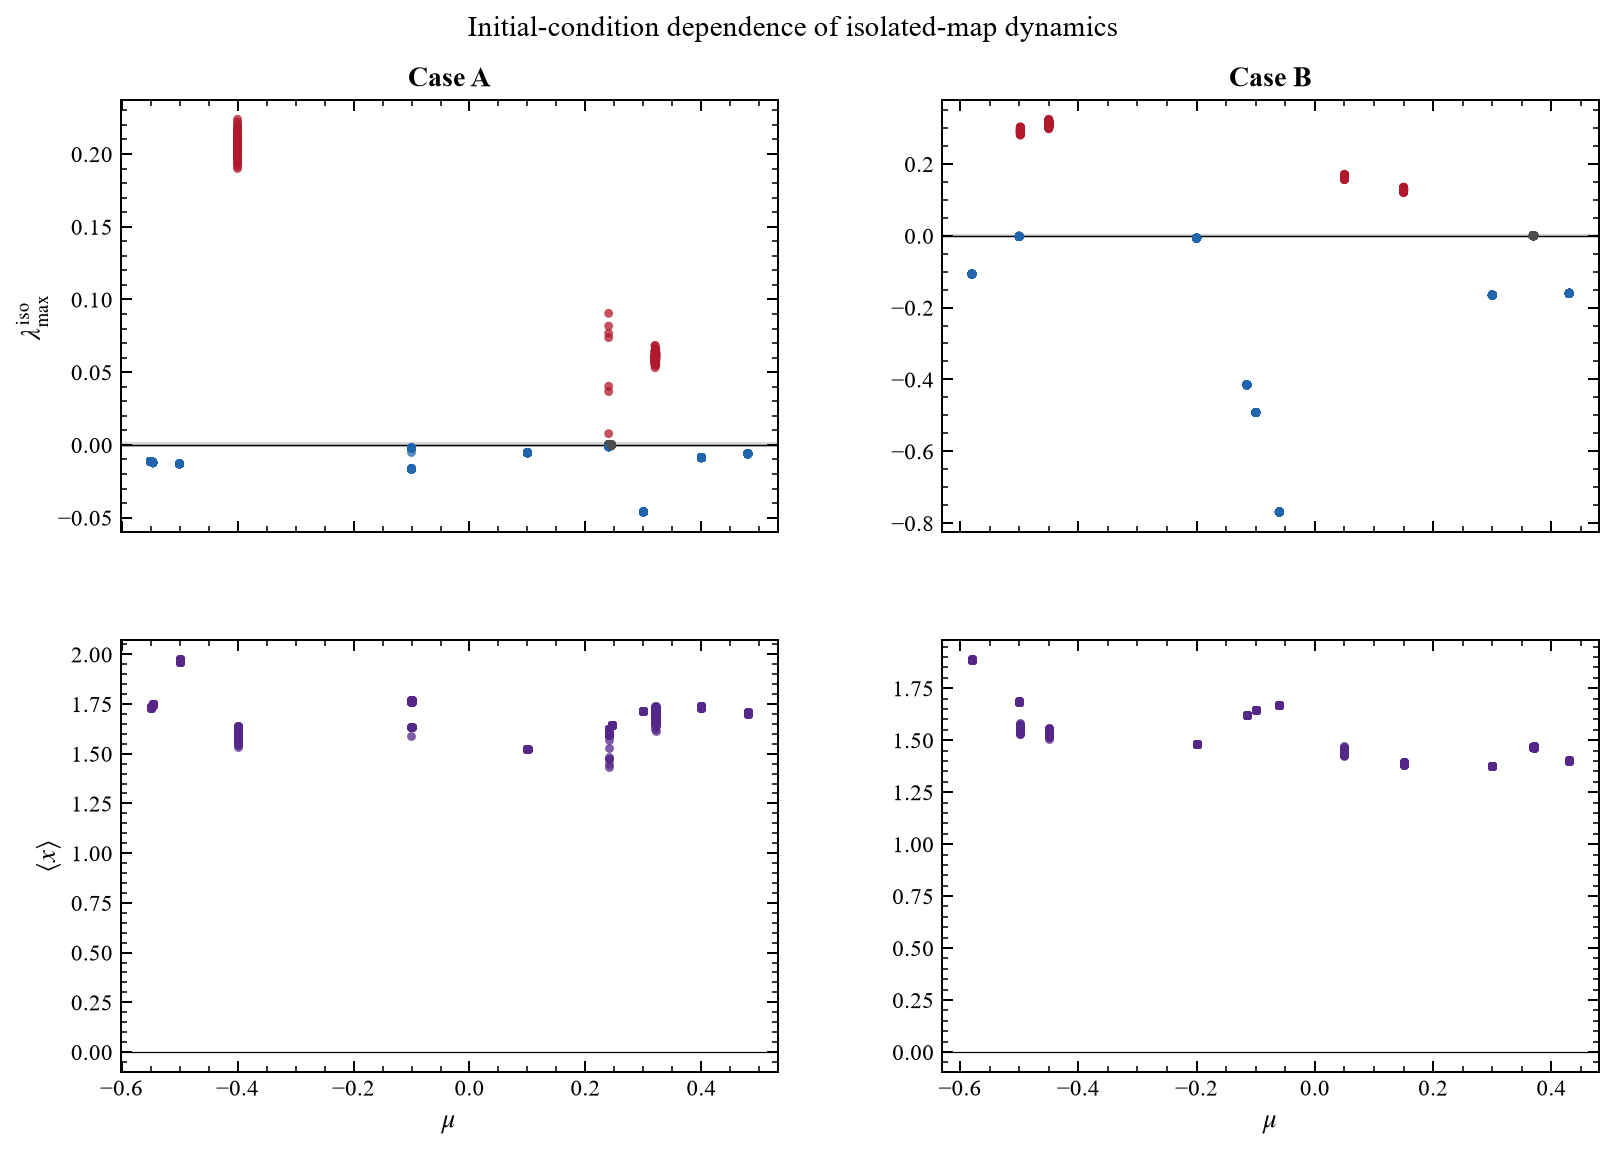


Possible coexistence of different dynamical stability classes was detected:


,case,mu,number_of_classes,observed_classes,multiple_stability_classes
6,A,0.24,3,"chaotic, near_zero, periodic",True


In [14]:
# ============================================================
# COMPLETE MULTIPLE-INITIAL-CONDITION ANALYSIS
# ============================================================

# IMPORTANT:
# Change these limits only if the manuscript used a different
# initialization rectangle.
INITIAL_CONDITION_RECTANGLE = {
    "x": (-1.0, 1.0),
    "y": (-1.0, 1.0),
}

# Numerical settings
N_INITIAL_CONDITIONS = 100
MULTISTABILITY_TRANSIENT = 20_000
MULTISTABILITY_LYAPUNOV_ITERATIONS = 10_000
MULTISTABILITY_ORBIT_POINTS = 2_000
MULTISTABILITY_SEED = 20260903

# Base parameter values selected from dynamically relevant
# regions in the corrected Version 2 diagrams.
MU_TEST_BASE = {
    "A": [
        -0.55,
        -0.50,
        -0.40,
        -0.10,
        0.10,
        0.24,
        0.30,
        0.32,
        0.40,
        0.48,
    ],
    "B": [
        -0.58,
        -0.50,
        -0.45,
        -0.20,
        -0.10,
        -0.06,
        0.05,
        0.15,
        0.30,
        0.37,
        0.43,
    ],
}


def build_mu_test_values(
    base_values,
    representative_values=None,
    decimals=6,
):
    """
    Combine targeted parameter values with the automatically
    verified representative values.

    Duplicate values are removed and the final values are sorted.
    """

    combined = {
        "A": list(base_values["A"]),
        "B": list(base_values["B"]),
    }

    if representative_values is not None:
        for case_name in ("A", "B"):
            for regime in (
                "periodic",
                "near_zero",
                "chaotic",
            ):
                mu = representative_values[
                    case_name
                ].get(regime)

                if (
                    mu is not None
                    and np.isfinite(mu)
                ):
                    combined[
                        case_name
                    ].append(float(mu))

    for case_name in ("A", "B"):
        combined[case_name] = sorted(
            {
                round(float(mu), decimals)
                for mu in combined[case_name]
            }
        )

    return combined


# Include automatically verified representative values if the
# variable exists. Otherwise, use only MU_TEST_BASE.
if "VERIFIED_REPRESENTATIVE_MU" in globals():
    MU_TEST = build_mu_test_values(
        MU_TEST_BASE,
        representative_values=(
            VERIFIED_REPRESENTATIVE_MU
        ),
    )
else:
    MU_TEST = build_mu_test_values(
        MU_TEST_BASE,
        representative_values=None,
    )

print("Parameter values used in the multistability analysis:")

for case_name in ("A", "B"):
    print(
        f"Case {case_name}: "
        f"{MU_TEST[case_name]}"
    )


def multistability_test(
    case_name,
    mu_values,
    n_initial_conditions=N_INITIAL_CONDITIONS,
    rectangle=INITIAL_CONDITION_RECTANGLE,
    n_transient=MULTISTABILITY_TRANSIENT,
    n_lyapunov=MULTISTABILITY_LYAPUNOV_ITERATIONS,
    n_orbit_points=MULTISTABILITY_ORBIT_POINTS,
    seed=MULTISTABILITY_SEED,
):
    """
    Test initial-condition dependence at selected mu values.

    For every initial condition, the routine records:
    - largest Lyapunov exponent;
    - Lyapunov-based dynamical classification;
    - asymptotic coordinate means and standard deviations;
    - attractor coordinate ranges;
    - number of distinct post-transient points;
    - path length and median step length.
    """

    parameters = CASES[case_name]

    # Case-specific reproducible random-number generator.
    case_offset = 0 if case_name == "A" else 1

    local_rng = np.random.default_rng(
        seed + case_offset
    )

    rows = []

    for mu in mu_values:
        print(
            f"Case {case_name}, "
            f"mu={mu:.6f}"
        )

        for initial_condition_id in range(
            n_initial_conditions
        ):
            x0 = local_rng.uniform(
                *rectangle["x"]
            )

            y0 = local_rng.uniform(
                *rectangle["y"]
            )

            exponent, exponent_valid = (
                largest_lyapunov(
                    mu,
                    parameters["a"],
                    parameters["b"],
                    x0=x0,
                    y0=y0,
                    n_transient=n_transient,
                    n_iter=n_lyapunov,
                )
            )

            xs, ys, orbit_valid = (
                compute_orbit(
                    mu,
                    parameters["a"],
                    parameters["b"],
                    x0=x0,
                    y0=y0,
                    n_transient=n_transient,
                    n_keep=n_orbit_points,
                )
            )

            if (
                exponent_valid
                and np.isfinite(exponent)
            ):
                dynamical_class = (
                    classify_exponent(
                        exponent,
                        tolerance=LAMBDA_TOL,
                    )
                )
            else:
                dynamical_class = "undefined"

            if orbit_valid:
                geometry = orbit_geometry_metrics(
                    xs,
                    ys,
                )

                mean_x = float(np.mean(xs))
                mean_y = float(np.mean(ys))
                std_x = float(np.std(xs))
                std_y = float(np.std(ys))

            else:
                geometry = {
                    "distinct_points": 0,
                    "x_range": np.nan,
                    "y_range": np.nan,
                    "path_length": np.nan,
                    "median_step": np.nan,
                }

                mean_x = np.nan
                mean_y = np.nan
                std_x = np.nan
                std_y = np.nan

            rows.append(
                {
                    "case": case_name,
                    "mu": mu,
                    "initial_condition_id": (
                        initial_condition_id
                    ),
                    "x0": x0,
                    "y0": y0,
                    "lambda_max": exponent,
                    "dynamical_class": (
                        dynamical_class
                    ),
                    "mean_x": mean_x,
                    "std_x": std_x,
                    "mean_y": mean_y,
                    "std_y": std_y,
                    "x_range": geometry[
                        "x_range"
                    ],
                    "y_range": geometry[
                        "y_range"
                    ],
                    "distinct_orbit_points": (
                        geometry[
                            "distinct_points"
                        ]
                    ),
                    "path_length": geometry[
                        "path_length"
                    ],
                    "median_step": geometry[
                        "median_step"
                    ],
                    "exponent_valid": (
                        exponent_valid
                    ),
                    "orbit_valid": orbit_valid,
                    "valid": bool(
                        exponent_valid
                        and orbit_valid
                    ),
                }
            )

    return pd.DataFrame(rows)


# ============================================================
# RUN THE MULTISTABILITY CALCULATION
# ============================================================

multistability_frames = []

for case_name in ("A", "B"):
    case_results = multistability_test(
        case_name,
        MU_TEST[case_name],
    )

    multistability_frames.append(
        case_results
    )

multistability_results = pd.concat(
    multistability_frames,
    ignore_index=True,
)

multistability_results.to_csv(
    OUTDIR
    / "multistability_initial_conditions.csv",
    index=False,
)

print(
    "\nMultistability calculation completed."
)


# ============================================================
# SUMMARY OF LYAPUNOV AND ATTRACTOR STATISTICS
# ============================================================

multistability_summary = (
    multistability_results
    .groupby(["case", "mu"])
    .agg(
        initial_conditions=(
            "initial_condition_id",
            "count",
        ),
        valid_results=(
            "valid",
            "sum",
        ),
        lambda_min=(
            "lambda_max",
            "min",
        ),
        lambda_max=(
            "lambda_max",
            "max",
        ),
        lambda_mean=(
            "lambda_max",
            "mean",
        ),
        lambda_std=(
            "lambda_max",
            "std",
        ),
        mean_x_min=(
            "mean_x",
            "min",
        ),
        mean_x_max=(
            "mean_x",
            "max",
        ),
        mean_y_min=(
            "mean_y",
            "min",
        ),
        mean_y_max=(
            "mean_y",
            "max",
        ),
        x_range_min=(
            "x_range",
            "min",
        ),
        x_range_max=(
            "x_range",
            "max",
        ),
        y_range_min=(
            "y_range",
            "min",
        ),
        y_range_max=(
            "y_range",
            "max",
        ),
        distinct_points_min=(
            "distinct_orbit_points",
            "min",
        ),
        distinct_points_max=(
            "distinct_orbit_points",
            "max",
        ),
    )
    .reset_index()
)

multistability_summary.to_csv(
    OUTDIR
    / "multistability_summary.csv",
    index=False,
)

display(
    multistability_summary
)


# ============================================================
# COUNT DYNAMICAL CLASSES FOR EACH PARAMETER VALUE
# ============================================================

class_count_table = (
    multistability_results
    .groupby(
        [
            "case",
            "mu",
            "dynamical_class",
        ]
    )
    .size()
    .rename("count")
    .reset_index()
)

class_count_table[
    "fraction"
] = class_count_table.groupby(
    ["case", "mu"]
)["count"].transform(
    lambda values: (
        values / values.sum()
    )
)

class_count_table.to_csv(
    OUTDIR
    / "multistability_class_counts.csv",
    index=False,
)

display(
    class_count_table
)


# ============================================================
# IDENTIFY POSSIBLE COEXISTENCE OF STABILITY CLASSES
# ============================================================

coexistence_summary = (
    class_count_table
    .groupby(["case", "mu"])
    .agg(
        number_of_classes=(
            "dynamical_class",
            "nunique",
        ),
        observed_classes=(
            "dynamical_class",
            lambda values: ", ".join(
                sorted(set(values))
            ),
        ),
    )
    .reset_index()
)

coexistence_summary[
    "multiple_stability_classes"
] = (
    coexistence_summary[
        "number_of_classes"
    ] > 1
)

coexistence_summary.to_csv(
    OUTDIR
    / "multistability_coexistence_summary.csv",
    index=False,
)

display(
    coexistence_summary
)


# ============================================================
# PLOT LYAPUNOV EXPONENT AND ATTRACTOR MEAN
# ============================================================

def plot_multistability_results(
    data,
):
    """
    Plot the initial-condition dependence of:
    1. the largest Lyapunov exponent;
    2. the asymptotic mean of x.
    """

    figure, axes = plt.subplots(
        2,
        2,
        figsize=(10.5, 7.5),
        sharex="col",
    )

    plot_colors = {
        "periodic": NEGATIVE_COLOR,
        "near_zero": NEUTRAL_COLOR,
        "chaotic": POSITIVE_COLOR,
        "undefined": "#bdbdbd",
    }

    for column, case_name in enumerate(
        ("A", "B")
    ):
        subset = data.loc[
            data["case"] == case_name
        ].copy()

        unique_mu = np.sort(
            subset["mu"].unique()
        )

        if len(unique_mu) > 1:
            jitter_width = (
                0.04
                * np.min(
                    np.diff(unique_mu)
                )
            )
        else:
            jitter_width = 0.003

        local_rng = np.random.default_rng(
            MULTISTABILITY_SEED
            + 100
            + column
        )

        jitter = local_rng.uniform(
            -jitter_width,
            jitter_width,
            size=len(subset),
        )

        plotted_mu = (
            subset["mu"].to_numpy()
            + jitter
        )

        colors = subset[
            "dynamical_class"
        ].map(
            plot_colors
        ).fillna(
            "#bdbdbd"
        ).to_numpy()

        axes[0, column].axhspan(
            -LAMBDA_TOL,
            LAMBDA_TOL,
            color="#d9d9d9",
            zorder=0,
        )

        axes[0, column].axhline(
            0.0,
            color="black",
            linewidth=0.65,
            zorder=1,
        )

        axes[0, column].scatter(
            plotted_mu,
            subset[
                "lambda_max"
            ].to_numpy(),
            color=colors,
            s=16,
            alpha=0.75,
            linewidths=0,
            zorder=2,
        )

        axes[1, column].axhline(
            0.0,
            color="black",
            linewidth=0.55,
            zorder=1,
        )

        axes[1, column].scatter(
            plotted_mu,
            subset[
                "mean_x"
            ].to_numpy(),
            color="#542788",
            s=16,
            alpha=0.75,
            linewidths=0,
            zorder=2,
        )

        axes[0, column].set_title(
            f"Case {case_name}"
        )

        axes[1, column].set_xlabel(
            r"$\mu$"
        )

    axes[0, 0].set_ylabel(
        r"$\lambda_{\max}^{\mathrm{iso}}$"
    )

    axes[1, 0].set_ylabel(
        r"$\langle x\rangle$"
    )

    figure.suptitle(
        "Initial-condition dependence of isolated-map dynamics"
    )

    figure.subplots_adjust(
        left=0.10,
        right=0.98,
        bottom=0.10,
        top=0.91,
        wspace=0.25,
        hspace=0.25,
    )

    for axis in axes.flat:
        axis.tick_params(which="both", direction="in", top=True,
                         right=True, labelsize=10.5)
        axis.xaxis.label.set_size(12)
        axis.yaxis.label.set_size(12)
        axis.minorticks_on()

    figure.savefig(
        OUTDIR
        / "multistability_lyapunov_and_mean.png",
        dpi=600,
        bbox_inches="tight",
    )

    figure.savefig(
        OUTDIR
        / "multistability_lyapunov_and_mean.pdf",
        bbox_inches="tight",
    )

    plt.show()

    return figure, axes


figure_multistability, axes_multistability = (
    plot_multistability_results(
        multistability_results
    )
)


# ============================================================
# FINAL REPORT
# ============================================================

possible_class_coexistence = (
    coexistence_summary.loc[
        coexistence_summary[
            "multiple_stability_classes"
        ]
    ]
)

if possible_class_coexistence.empty:
    print(
        "\nNo coexistence of different Lyapunov stability "
        "classes was detected at the tested parameter values."
    )

    print(
        "This does not rule out geometrically distinct "
        "coexisting attractors with similar Lyapunov exponents."
    )

else:
    print(
        "\nPossible coexistence of different dynamical "
        "stability classes was detected:"
    )

    display(
        possible_class_coexistence
    )

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


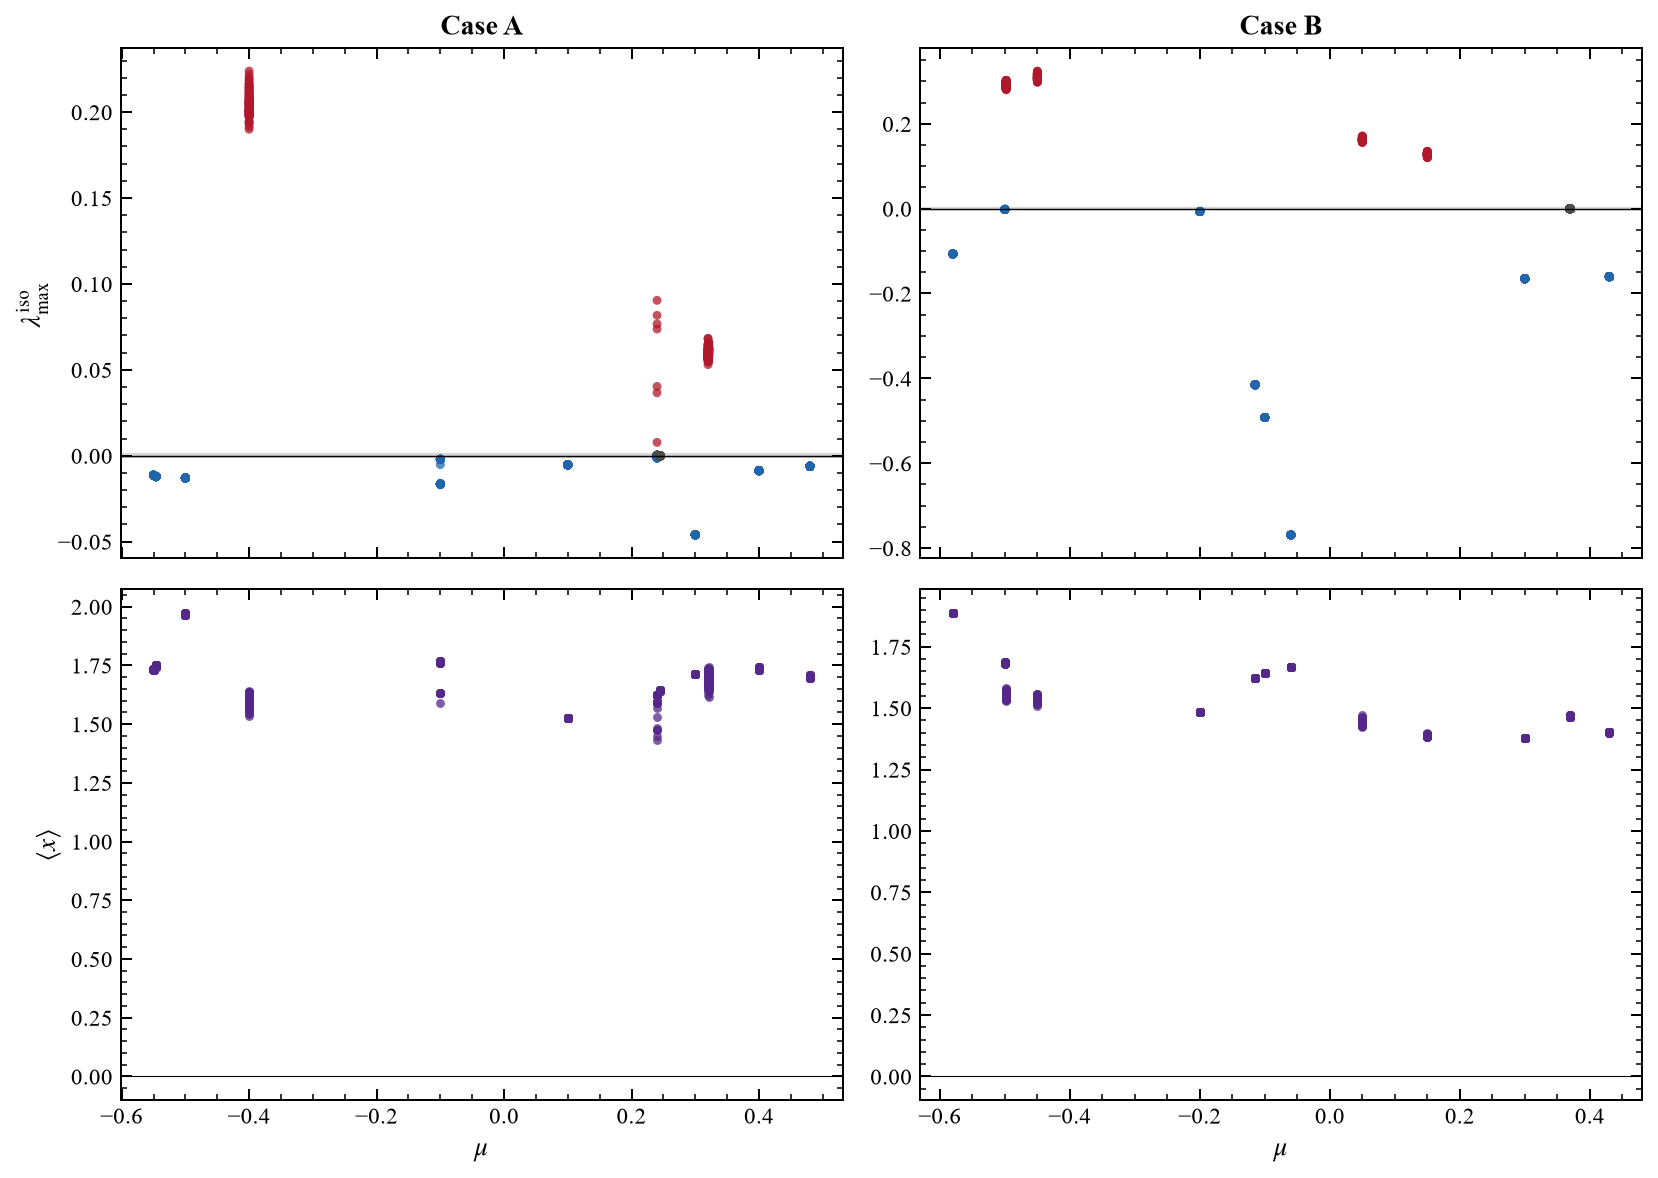

In [15]:
def plot_multistability(data):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(10.5, 7.5),
        sharex="col",
    )

    for column, case_name in enumerate(("A", "B")):
        subset = data.loc[data["case"] == case_name].copy()
        unique_mu = np.sort(subset["mu"].unique())

        if len(unique_mu) > 1:
            jitter_width = 0.04*np.min(np.diff(unique_mu))
        else:
            jitter_width = 0.003

        local_rng = np.random.default_rng(SEED+column)
        jitter = local_rng.uniform(
            -jitter_width,
            jitter_width,
            size=len(subset),
        )
        plotted_mu = subset["mu"].to_numpy()+jitter
        values = subset["lambda_max"].to_numpy()

        colors = np.full(len(subset), NEUTRAL_COLOR, dtype=object)
        colors[values < -LAMBDA_TOL] = NEGATIVE_COLOR
        colors[values > LAMBDA_TOL] = POSITIVE_COLOR

        axes[0, column].axhspan(
            -LAMBDA_TOL,
            LAMBDA_TOL,
            color=NEUTRAL_BAND_COLOR,
        )
        axes[0, column].axhline(0.0, color="black", linewidth=0.65)
        axes[0, column].scatter(
            plotted_mu,
            values,
            color=colors,
            s=16,
            alpha=0.75,
            linewidths=0,
        )

        axes[1, column].axhline(0.0, color="black", linewidth=0.5)
        axes[1, column].scatter(
            plotted_mu,
            subset["mean_x"].to_numpy(),
            color="#542788",
            s=16,
            alpha=0.75,
            linewidths=0,
        )

        axes[0, column].set_title(f"Case {case_name}")
        axes[1, column].set_xlabel(r"$\mu$")

    axes[0, 0].set_ylabel(r"$\lambda_{\max}^{\mathrm{iso}}$")
    axes[1, 0].set_ylabel(r"$\langle x\rangle$")

    fig.tight_layout()
    for axis in axes.flat:
        axis.tick_params(which="both", direction="in", top=True,
                         right=True, labelsize=10.5)
        axis.xaxis.label.set_size(12)
        axis.yaxis.label.set_size(12)
        axis.minorticks_on()

    fig.savefig(OUTDIR/"multistability_lyapunov_and_mean.png")
    fig.savefig(OUTDIR/"multistability_lyapunov_and_mean.pdf")
    fig.savefig(OUTDIR/"multistability_lyapunov_and_mean.eps")
    plt.show()
    return fig, axes


fig_multi, axes_multi = plot_multistability(multistability_results)

## Reporting checklist

Report the exact map equation, analytical derivative, Jacobian, initial condition, parameter step, discarded transient, Lyapunov accumulation length, escape criterion, and $\lambda_{\mathrm{tol}}$. State whether each parameter value was initialized independently. For multistability tests, report the initialization rectangle and number of initial conditions.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


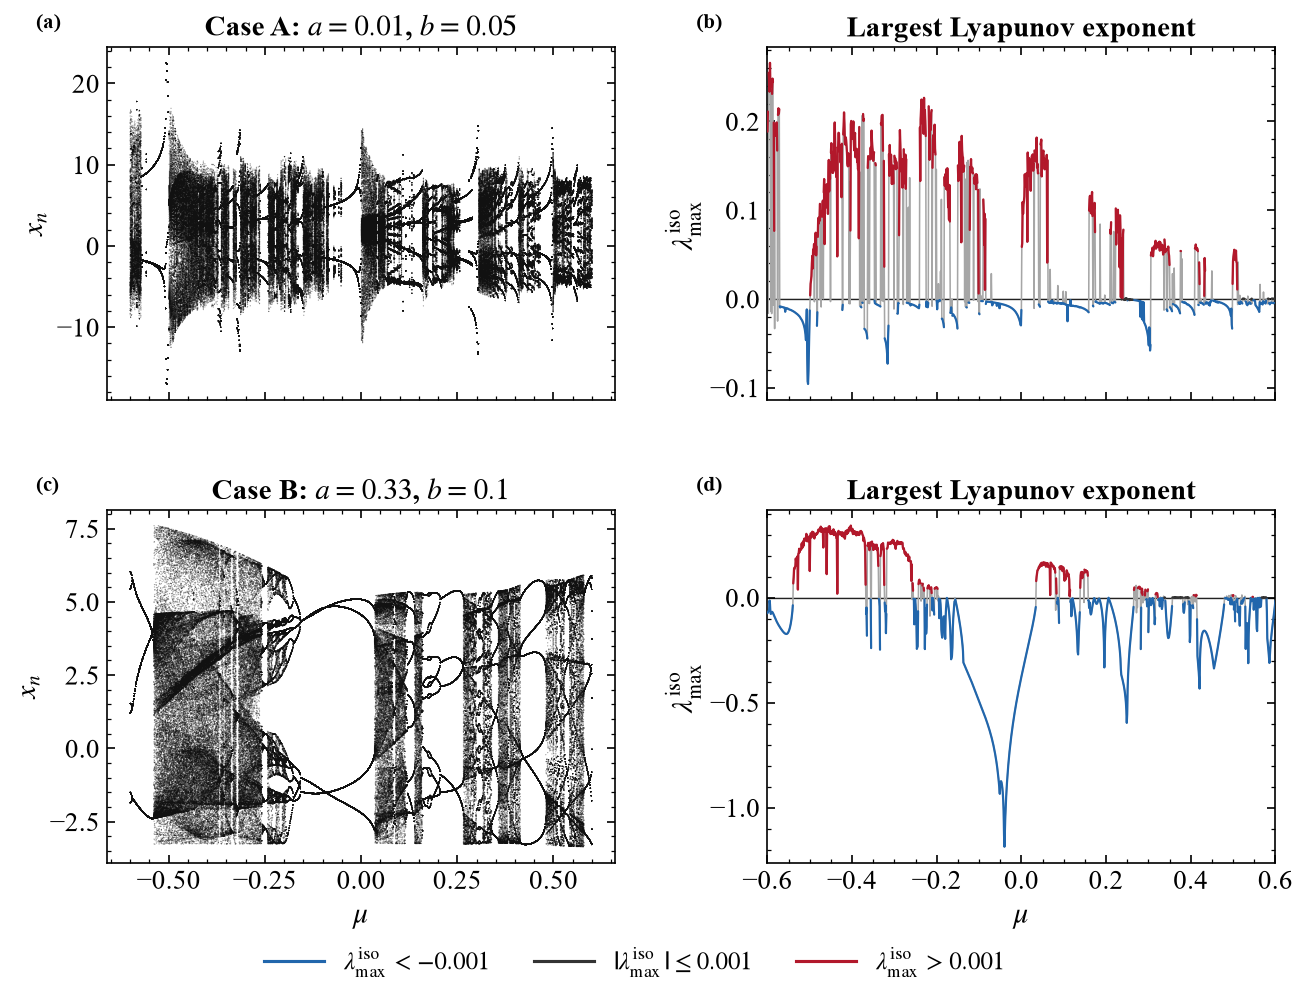

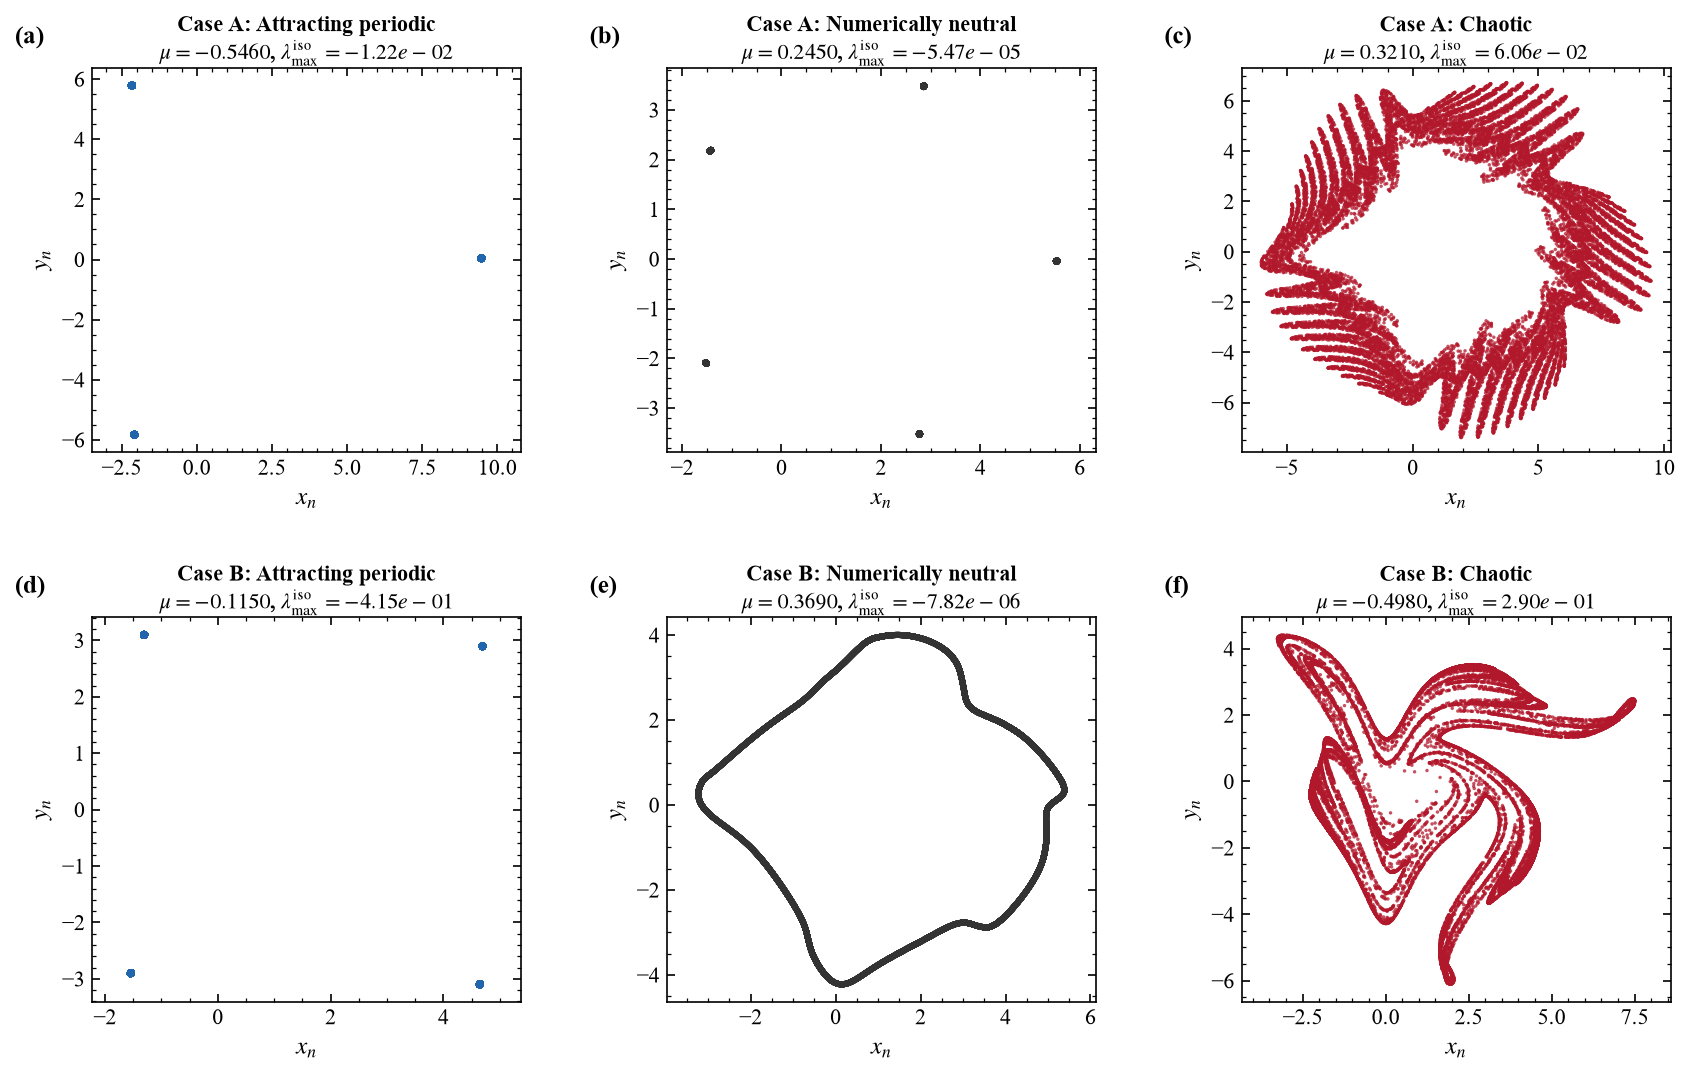

,case,requested_regime,mu,lambda_max,final_regime,orbit_valid,agreement
0,A,periodic,-0.546,-0.012176,periodic,True,True
1,A,near_zero,0.245,-0.000055,near_zero,True,True
2,A,chaotic,0.321,0.060565,chaotic,True,True
3,B,periodic,-0.115,-0.415160,periodic,True,True
4,B,near_zero,0.369,-0.000008,near_zero,True,True
5,B,chaotic,-0.498,0.290029,chaotic,True,True


All publication phase portraits retained their requested Lyapunov classifications.


In [21]:
# ============================================================
# PUBLICATION-READY FIGURES
#
# Figure 1:
#   Bifurcation diagrams and continuous Lyapunov curves
#
# Figure 2:
#   Automatically selected representative phase portraits
#
# Required objects:
#   results
#   CASES
#   VERIFIED_REPRESENTATIVE_MU
#   compute_orbit
#   largest_lyapunov
#   classify_exponent
#   X0, Y0
#   LAMBDA_TOL
#   OUTDIR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path


# ============================================================
# 1. PUBLICATION STYLE
# ============================================================

# Adjust these values if the journal specifies another font.
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [
            "Times New Roman",
            "Times",
            "DejaVu Serif",
        ],
        "mathtext.fontset": "stix",
        "font.size": 16,
        "axes.labelsize": 14,
        "axes.titlesize": 14,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.size": 4,
        "ytick.major.size": 4,
        "xtick.minor.size": 2,
        "ytick.minor.size": 2,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.top": True,
        "ytick.right": True,
        "legend.fontsize": 12,
        "legend.frameon": False,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)


# ============================================================
# 2. COLORS
# ============================================================

PERIODIC_COLOR = "#2166AC"
#NEUTRAL_COLOR = "#4D4D4D"
CHAOTIC_COLOR = "#B2182B"
BIFURCATION_COLOR = "#111111"
NEUTRAL_BAND_COLOR = "#D9D9D9"
REFERENCE_LINE_COLOR = "#222222"
NEUTRAL_COLOR = "#333333"


# ============================================================
# 3. SUPPORT BOTH OLD AND NEW RESULT-DICTIONARY NAMES
# ============================================================

def get_result_array(result, preferred_key, alternative_key):
    """
    Retrieve an array while supporting both versions of the
    result-dictionary naming convention.
    """

    if preferred_key in result:
        return np.asarray(
            result[preferred_key]
        )

    if alternative_key in result:
        return np.asarray(
            result[alternative_key]
        )

    raise KeyError(
        f"Neither '{preferred_key}' nor "
        f"'{alternative_key}' exists in results."
    )


def extract_result_arrays(result):
    """
    Return the parameter, exponent, and bifurcation arrays.
    """

    mu = get_result_array(
        result,
        "mu",
        "mu",
    )

    exponent = get_result_array(
        result,
        "lambda_max",
        "ly",
    )

    bifurcation_mu = get_result_array(
        result,
        "bifurcation_mu",
        "bm",
    )

    bifurcation_x = get_result_array(
        result,
        "bifurcation_x",
        "bx",
    )

    return (
        mu,
        exponent,
        bifurcation_mu,
        bifurcation_x,
    )


# ============================================================
# 4. CONTINUOUS LYAPUNOV CURVE
# ============================================================

def plot_continuous_lyapunov(
    axis,
    mu,
    exponent,
    tolerance=LAMBDA_TOL,
):
    """
    Plot the largest Lyapunov exponent as continuous lines.

    The full curve is first drawn in light gray to preserve
    continuity. Negative, neutral, and positive portions are
    then overlaid using separate colors.

    NaN values generate genuine gaps in the curve.
    """

    mu = np.asarray(mu)
    exponent = np.asarray(exponent)

    finite = (
        np.isfinite(mu)
        & np.isfinite(exponent)
    )

    # Neutral tolerance band
    axis.axhspan(
        -tolerance,
        tolerance,
        color=NEUTRAL_BAND_COLOR,
        alpha=0.60,
        linewidth=0,
        zorder=0,
    )

    # Zero reference line
    axis.axhline(
        0.0,
        color=REFERENCE_LINE_COLOR,
        linewidth=0.65,
        linestyle="-",
        zorder=1,
    )

    # Underlying continuous curve
    full_curve = np.where(
        finite,
        exponent,
        np.nan,
    )

    axis.plot(
        mu,
        full_curve,
        color="#A6A6A6",
        linewidth=0.75,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=2,
    )

    # Classification masks
    negative_mask = (
        finite
        & (exponent < -tolerance)
    )

    neutral_mask = (
        finite
        & (
            np.abs(exponent)
            <= tolerance
        )
    )

    positive_mask = (
        finite
        & (exponent > tolerance)
    )

    # Mask each category separately.
    negative_values = np.where(
        negative_mask,
        exponent,
        np.nan,
    )

    neutral_values = np.where(
        neutral_mask,
        exponent,
        np.nan,
    )

    positive_values = np.where(
        positive_mask,
        exponent,
        np.nan,
    )

    # Colored continuous portions
    axis.plot(
        mu,
        negative_values,
        color=PERIODIC_COLOR,
        linewidth=1.05,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=3,
    )

    axis.plot(
        mu,
        neutral_values,
        color=NEUTRAL_COLOR,
        linewidth=1.25,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=4,
    )

    axis.plot(
        mu,
        positive_values,
        color=CHAOTIC_COLOR,
        linewidth=1.10,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=5,
    )

    axis.set_xlim(
        np.nanmin(mu),
        np.nanmax(mu),
    )

    axis.minorticks_on()


# ============================================================
# 5. FIGURE 1:
#    BIFURCATION DIAGRAMS AND CONTINUOUS LYAPUNOV CURVES
# ============================================================

def make_publication_bifurcation_lyapunov_figure(
    results,
    filename_stem=(
        "publication_bifurcation_lyapunov"
    ),
):
    """
    Create a publication-ready four-panel figure.

    Left column:
        bifurcation diagrams.

    Right column:
        continuous largest-Lyapunov curves.
    """

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(8.8, 6.8),
        sharex="col",
    )

    panel_labels = (
        "(a)",
        "(b)",
        "(c)",
        "(d)",
    )

    for row, case_name in enumerate(
        ("A", "B")
    ):
        parameters = CASES[case_name]
        result = results[case_name]

        (
            mu,
            exponent,
            bifurcation_mu,
            bifurcation_x,
        ) = extract_result_arrays(
            result
        )

        # ----------------------------------------
        # Bifurcation diagram
        # ----------------------------------------

        bifurcation_axis = axes[
            row,
            0,
        ]

        bifurcation_axis.scatter(
            bifurcation_mu,
            bifurcation_x,
            s=0.35,
            c=BIFURCATION_COLOR,
            alpha=0.40,
            edgecolors="none",
            linewidths=0,
            rasterized=True,
        )

        bifurcation_axis.set_ylabel(
            r"$x_n$"
        )

        bifurcation_axis.set_title(
            rf"Case {case_name}: "
            rf"$a={parameters['a']}$, "
            rf"$b={parameters['b']}$",
            pad=5,
        )

        bifurcation_axis.minorticks_on()

        # ----------------------------------------
        # Largest Lyapunov exponent
        # ----------------------------------------

        lyapunov_axis = axes[
            row,
            1,
        ]

        plot_continuous_lyapunov(
            lyapunov_axis,
            mu,
            exponent,
            tolerance=LAMBDA_TOL,
        )

        lyapunov_axis.set_ylabel(
            r"$\lambda_{\max}^{\mathrm{iso}}$"
        )

        lyapunov_axis.set_title(
            "Largest Lyapunov exponent",
            pad=5,
        )


    for axis in axes.flat:
        axis.tick_params(which="both", direction="in", top=True,
                         right=True, labelsize=13)
        axis.minorticks_on()

    # Bottom horizontal labels
    axes[1, 0].set_xlabel(
        r"$\mu$"
    )

    axes[1, 1].set_xlabel(
        r"$\mu$"
    )

    # Panel labels
    for index, axis in enumerate(
        axes.flat
    ):
        axis.text(
            -0.14,
            1.04,
            panel_labels[index],
            transform=axis.transAxes,
            fontsize=10,
            fontweight="bold",
            ha="left",
            va="bottom",
        )

    # Shared legend
    legend_handles = [
        Line2D(
            [0],
            [0],
            color=PERIODIC_COLOR,
            linewidth=1.5,
            label=(
                rf"$\lambda_{{\max}}^"
                rf"{{\mathrm{{iso}}}}"
                rf"<-{LAMBDA_TOL:g}$"
            ),
        ),
        Line2D(
            [0],
            [0],
            color=NEUTRAL_COLOR,
            linewidth=1.5,
            label=(
                rf"$|\lambda_{{\max}}^"
                rf"{{\mathrm{{iso}}}}|"
                rf"\leq {LAMBDA_TOL:g}$"
            ),
        ),
        Line2D(
            [0],
            [0],
            color=CHAOTIC_COLOR,
            linewidth=1.5,
            label=(
                rf"$\lambda_{{\max}}^"
                rf"{{\mathrm{{iso}}}}"
                rf">{LAMBDA_TOL:g}$"
            ),
        ),
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
        bbox_to_anchor=(0.5, 0.005),
        handlelength=2.4,
        columnspacing=1.7,
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.985,
        bottom=0.14,
        top=0.94,
        wspace=0.30,
        hspace=0.31,
    )

    # Vector output
    fig.savefig(
        OUTDIR/f"{filename_stem}.pdf",
        bbox_inches="tight",
    )

    # High-resolution bitmap
    fig.savefig(
        OUTDIR/f"{filename_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    # Optional EPS output
    fig.savefig(
        OUTDIR/f"{filename_stem}.eps",
        bbox_inches="tight",
    )

    plt.show()

    return fig, axes


figure_dynamics, axes_dynamics = (
    make_publication_bifurcation_lyapunov_figure(
        results
    )
)


# ============================================================
# 6. FIGURE 2:
#    PUBLICATION-READY REPRESENTATIVE PHASE PORTRAITS
# ============================================================

def make_publication_phase_portrait_figure(
    selection,
    n_transient=50_000,
    n_keep=20_000,
    lyapunov_iterations=50_000,
    filename_stem=(
        "publication_representative_phase_portraits"
    ),
):
    """
    Create publication-ready phase portraits using the
    automatically verified parameter selections.
    """

    regimes = (
        "periodic",
        "near_zero",
        "chaotic",
    )

    regime_titles = {
    "periodic": "Attracting periodic",
    "near_zero": "Numerically neutral",
    "chaotic": "Chaotic",
    }


    regime_colors = {
        "periodic": PERIODIC_COLOR,
        "near_zero": NEUTRAL_COLOR,
        "chaotic": CHAOTIC_COLOR,
    }

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(11.5, 7.5),
    )

    panel_labels = (
        "(a)",
        "(b)",
        "(c)",
        "(d)",
        "(e)",
        "(f)",
    )

    summary_records = []

    for row, case_name in enumerate(
        ("A", "B")
    ):
        parameters = CASES[case_name]

        for column, requested_regime in enumerate(
            regimes
        ):
            axis = axes[
                row,
                column,
            ]

            panel_index = (
                3 * row + column
            )

            mu = selection[
                case_name
            ].get(
                requested_regime
            )

            # ----------------------------------------
            # No representative found
            # ----------------------------------------

            if (
                mu is None
                or not np.isfinite(mu)
            ):
                axis.text(
                    0.5,
                    0.5,
                    "No robust\nparameter interval",
                    ha="center",
                    va="center",
                    transform=axis.transAxes,
                    fontsize=14,
                )

                axis.set_title(
                    f"Case {case_name}: "
                    f"{regime_titles[requested_regime]}",
                    fontsize=11,
                )

                axis.set_xticks([])
                axis.set_yticks([])

                summary_records.append(
                    {
                        "case": case_name,
                        "requested_regime": (
                            requested_regime
                        ),
                        "mu": np.nan,
                        "lambda_max": np.nan,
                        "final_regime": (
                            "not_selected"
                        ),
                        "orbit_valid": False,
                        "agreement": False,
                    }
                )

                continue

            # ----------------------------------------
            # Long final orbit
            # ----------------------------------------

            xs, ys, orbit_valid = (
                compute_orbit(
                    mu,
                    parameters["a"],
                    parameters["b"],
                    x0=X0,
                    y0=Y0,
                    n_transient=n_transient,
                    n_keep=n_keep,
                )
            )

            # ----------------------------------------
            # Long final Lyapunov calculation
            # ----------------------------------------

            exponent, exponent_valid = (
                largest_lyapunov(
                    mu,
                    parameters["a"],
                    parameters["b"],
                    x0=X0,
                    y0=Y0,
                    n_transient=n_transient,
                    n_iter=(
                        lyapunov_iterations
                    ),
                )
            )

            if (
                exponent_valid
                and np.isfinite(exponent)
            ):
                final_regime = (
                    classify_exponent(
                        exponent,
                        tolerance=LAMBDA_TOL,
                    )
                )
            else:
                final_regime = (
                    "undefined"
                )

            agreement = (
                final_regime
                == requested_regime
            )

            summary_records.append(
                {
                    "case": case_name,
                    "requested_regime": (
                        requested_regime
                    ),
                    "mu": mu,
                    "lambda_max": exponent,
                    "final_regime": (
                        final_regime
                    ),
                    "orbit_valid": (
                        orbit_valid
                    ),
                    "agreement": agreement,
                }
            )

            # ----------------------------------------
            # Plot phase portrait
            # ----------------------------------------

            if orbit_valid:
                if requested_regime == "periodic":
                    # Larger markers make finite-period points visible.
                    marker_size = 15.0
                    marker_alpha = 0.95
                elif requested_regime == "near_zero":
                    marker_size = 8.55
                    marker_alpha = 0.95
                else:
                    marker_size = 2.75
                    marker_alpha = 0.75

                axis.scatter(
                    xs,
                    ys,
                    s=marker_size,
                    color=regime_colors[
                        requested_regime
                    ],
                    alpha=marker_alpha,
                    linewidths=0,
                    edgecolors="none",
                    rasterized=True,
                )

            else:
                axis.text(
                    0.5,
                    0.5,
                    "Trajectory diverged",
                    ha="center",
                    va="center",
                    transform=axis.transAxes,
                    fontsize=10,
                )

            # ----------------------------------------
            # Compact title
            # ----------------------------------------

            if (
                exponent_valid
                and np.isfinite(exponent)
            ):
                numerical_line = (
                    rf"$\mu={mu:.4f}$, "
                    rf"$\lambda_{{\max}}^"
                    rf"{{\mathrm{{iso}}}}"
                    rf"={exponent:.2e}$"
                )
            else:
                numerical_line = (
                    rf"$\mu={mu:.4f}$, "
                    r"$\lambda_{\max}^{\mathrm{iso}}$ "
                    r"undefined"
                )

            axis.set_title(
                f"Case {case_name}: "
                f"{regime_titles[requested_regime]}"
                "\n"
                f"{numerical_line}",
                fontsize=10.5,
                pad=4,
            )

            axis.set_xlabel(
                r"$x_n$"
            )

            axis.set_ylabel(
                r"$y_n$"
            )

            axis.set_aspect(
                "equal",
                adjustable="datalim",
            )

            axis.minorticks_on()

            # Panel label
            axis.text(
                -0.18,
                1.05,
                panel_labels[panel_index],
                transform=axis.transAxes,
                fontsize=12,
                fontweight="bold",
                ha="left",
                va="bottom",
            )

    portrait_summary = pd.DataFrame(
        summary_records
    )

    for axis in axes.flat:
        axis.tick_params(which="both", direction="in", top=True,
                         right=True, labelsize=10.5)
        axis.xaxis.label.set_size(12)
        axis.yaxis.label.set_size(12)
        axis.minorticks_on()

    fig.subplots_adjust(
        left=0.075,
        right=0.99,
        bottom=0.09,
        top=0.92,
        wspace=0.34,
        hspace=0.43,
    )

    fig.savefig(
        OUTDIR/f"{filename_stem}.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        OUTDIR/f"{filename_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUTDIR/f"{filename_stem}.eps",
        bbox_inches="tight",
    )

    portrait_summary.to_csv(
        OUTDIR
        / "publication_phase_portrait_summary.csv",
        index=False,
    )

    plt.show()

    return (
        fig,
        axes,
        portrait_summary,
    )


(
    figure_portraits,
    axes_portraits,
    publication_portrait_summary,
) = make_publication_phase_portrait_figure(
    VERIFIED_REPRESENTATIVE_MU
)

display(
    publication_portrait_summary
)


# ============================================================
# 7. FINAL VALIDATION
# ============================================================

selected_portraits = (
    publication_portrait_summary.loc[
        publication_portrait_summary[
            "final_regime"
        ]
        != "not_selected"
    ]
)

if selected_portraits.empty:
    print(
        "No phase portraits were generated."
    )

elif selected_portraits[
    "agreement"
].all():
    print(
        "All publication phase portraits retained "
        "their requested Lyapunov classifications."
    )

else:
    print(
        "Warning: at least one published portrait "
        "requires classification review."
    )

    display(
        selected_portraits.loc[
            ~selected_portraits[
                "agreement"
            ]
        ]
    )

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


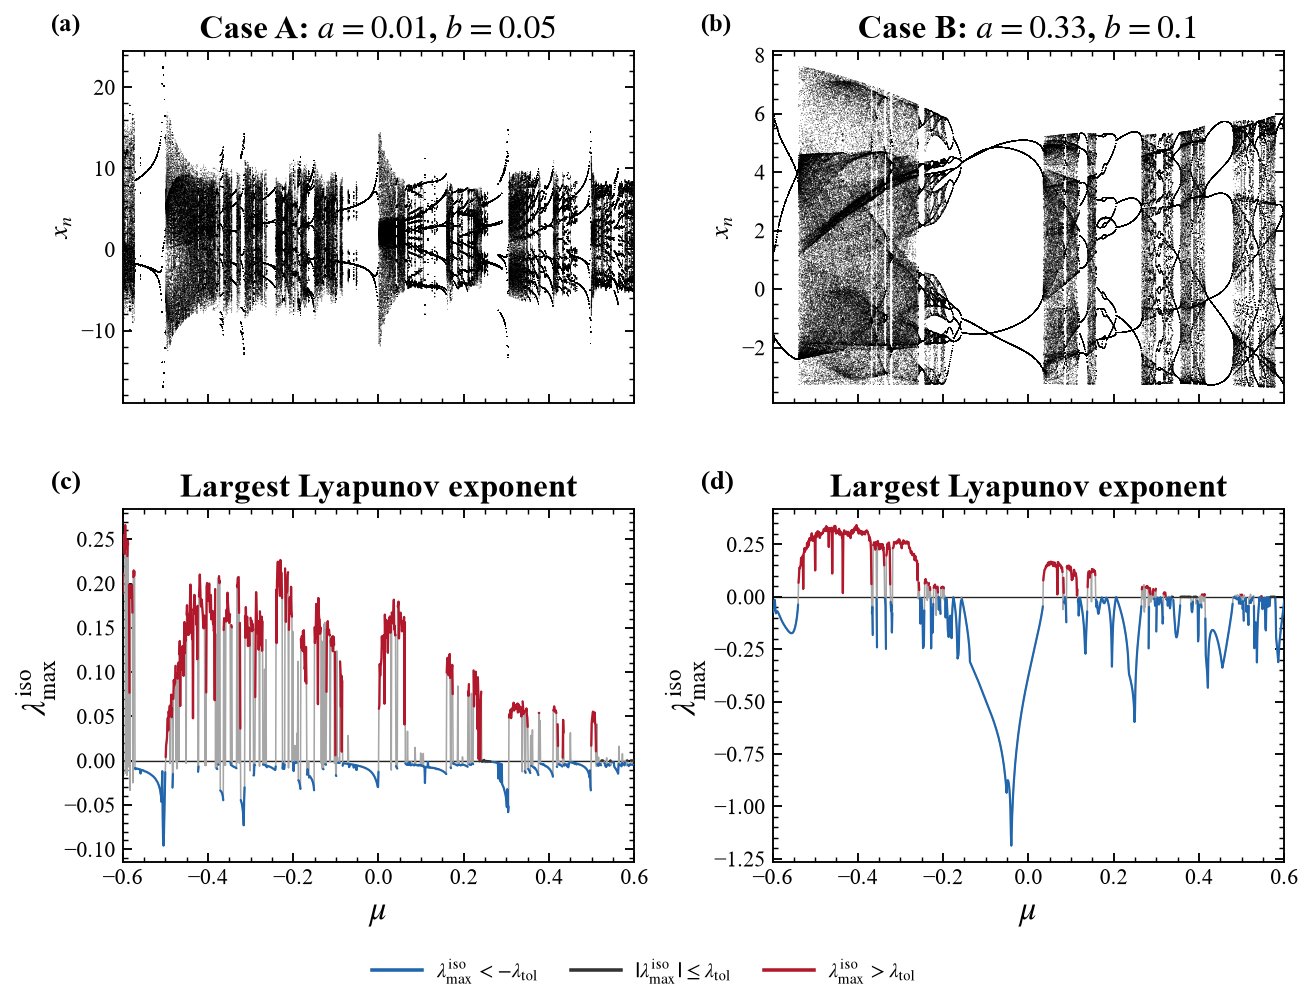


Rearranged isolated-map figure saved:
C:\Users\em18702\OneDrive - AUT University\GMAP\gm_version2_outputs\publication_bifurcation_lyapunov_vertical_comparison.pdf
C:\Users\em18702\OneDrive - AUT University\GMAP\gm_version2_outputs\publication_bifurcation_lyapunov_vertical_comparison.png
C:\Users\em18702\OneDrive - AUT University\GMAP\gm_version2_outputs\publication_bifurcation_lyapunov_vertical_comparison.eps


In [22]:
# ============================================================
# 5. FIGURE 1:
#    BIFURCATION DIAGRAMS ABOVE LYAPUNOV CURVES
# ============================================================
#
# Panel arrangement:
#
#   (a) Case A bifurcation     (b) Case B bifurcation
#   (c) Case A Lyapunov        (d) Case B Lyapunov
#
# Each Lyapunov-exponent plot is placed directly below its
# corresponding bifurcation diagram.
# ============================================================

def make_publication_bifurcation_lyapunov_figure(
    results,
    filename_stem=(
        "publication_bifurcation_"
        "lyapunov_vertical_comparison"
    ),
):
    """
    Create a publication-ready four-panel isolated-map figure.

    Top row
    -------
    Panel (a):
        Case A bifurcation diagram.

    Panel (b):
        Case B bifurcation diagram.

    Bottom row
    ----------
    Panel (c):
        Case A largest Lyapunov exponent.

    Panel (d):
        Case B largest Lyapunov exponent.
    """

    # --------------------------------------------------------
    # Check that both parameter cases are available.
    # --------------------------------------------------------

    for required_case in (
        "A",
        "B",
    ):
        if required_case not in results:
            raise KeyError(
                "The results dictionary does not contain "
                f"Case {required_case}."
            )

        if required_case not in CASES:
            raise KeyError(
                "The CASES dictionary does not contain "
                f"Case {required_case}."
            )

    # --------------------------------------------------------
    # Create the figure.
    #
    # sharex="col" ensures that the bifurcation and Lyapunov
    # panels for each case use the same horizontal axis.
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(
            8.8,
            6.8,
        ),
        sharex="col",
        squeeze=False,
    )

    panel_labels = {
        ("bifurcation", "A"): "(a)",
        ("bifurcation", "B"): "(b)",
        ("lyapunov", "A"): "(c)",
        ("lyapunov", "B"): "(d)",
    }

    case_columns = {
        "A": 0,
        "B": 1,
    }

    # --------------------------------------------------------
    # Generate both columns.
    # --------------------------------------------------------

    for case_name in (
        "A",
        "B",
    ):
        column = case_columns[
            case_name
        ]

        parameters = CASES[
            case_name
        ]

        result = results[
            case_name
        ]

        (
            mu,
            exponent,
            bifurcation_mu,
            bifurcation_x,
        ) = extract_result_arrays(
            result
        )

        # Convert all plotting inputs to one-dimensional arrays.
        mu = np.asarray(
            mu,
            dtype=float,
        ).ravel()

        exponent = np.asarray(
            exponent,
            dtype=float,
        ).ravel()

        bifurcation_mu = np.asarray(
            bifurcation_mu,
            dtype=float,
        ).ravel()

        bifurcation_x = np.asarray(
            bifurcation_x,
            dtype=float,
        ).ravel()

        # ----------------------------------------------------
        # Validate array lengths.
        # ----------------------------------------------------

        if mu.size != exponent.size:
            raise ValueError(
                f"Case {case_name}: mu and Lyapunov arrays "
                "must have the same length. Received "
                f"{mu.size} and {exponent.size}."
            )

        if (
            bifurcation_mu.size
            != bifurcation_x.size
        ):
            raise ValueError(
                f"Case {case_name}: bifurcation_mu and "
                "bifurcation_x must have the same length. "
                f"Received {bifurcation_mu.size} and "
                f"{bifurcation_x.size}."
            )

        finite_mu = mu[
            np.isfinite(
                mu
            )
        ]

        if finite_mu.size == 0:
            raise ValueError(
                f"Case {case_name}: the mu array contains "
                "no finite values."
            )

        mu_minimum = float(
            np.min(
                finite_mu
            )
        )

        mu_maximum = float(
            np.max(
                finite_mu
            )
        )

        # ====================================================
        # Top row: Bifurcation diagram
        # ====================================================

        bifurcation_axis = axes[
            0,
            column,
        ]

        finite_bifurcation = (
            np.isfinite(
                bifurcation_mu
            )
            & np.isfinite(
                bifurcation_x
            )
        )

        if not np.any(
            finite_bifurcation
        ):
            raise ValueError(
                f"Case {case_name}: no finite bifurcation "
                "points are available."
            )

        # The darker black color, increased point size, and
        # increased opacity improve visibility while preserving
        # the internal density of chaotic intervals.
        bifurcation_axis.scatter(
            bifurcation_mu[
                finite_bifurcation
            ],
            bifurcation_x[
                finite_bifurcation
            ],
            s=0.65,
            color="#000000",
            alpha=0.72,
            marker=".",
            edgecolors="none",
            linewidths=0.0,
            rasterized=True,
            zorder=2,
        )

        bifurcation_axis.set_facecolor(
            "white"
        )

        bifurcation_axis.grid(
            False
        )

        bifurcation_axis.set_xlim(
            mu_minimum,
            mu_maximum,
        )

        bifurcation_axis.set_ylabel(
            r"$x_n$",
            fontsize=13,
            labelpad=4,
        )

        bifurcation_axis.set_title(
            (
                rf"Case {case_name}: "
                rf"$a={parameters['a']}$, "
                rf"$b={parameters['b']}$"
            ),
            fontsize=16,
            pad=6,
        )

        bifurcation_axis.tick_params(
            which="major",
            direction="in",
            top=True,
            right=True,
            bottom=True,
            left=True,
            length=4.5,
            width=0.9,
            labelsize=8,
            labelbottom=False,
        )

        bifurcation_axis.tick_params(
            which="minor",
            direction="in",
            top=True,
            right=True,
            bottom=True,
            left=True,
            length=2.5,
            width=0.7,
        )

        bifurcation_axis.minorticks_on()

        for spine in (
            bifurcation_axis.spines.values()
        ):
            spine.set_linewidth(
                0.9
            )

        bifurcation_axis.text(
            -0.14,
            1.04,
            panel_labels[
                (
                    "bifurcation",
                    case_name,
                )
            ],
            transform=(
                bifurcation_axis.transAxes
            ),
            fontsize=12,
            fontweight="bold",
            ha="left",
            va="bottom",
        )

        # ====================================================
        # Bottom row: Largest Lyapunov exponent
        # ====================================================

        lyapunov_axis = axes[
            1,
            column,
        ]

        plot_continuous_lyapunov(
            lyapunov_axis,
            mu,
            exponent,
            tolerance=LAMBDA_TOL,
        )

        lyapunov_axis.set_xlim(
            mu_minimum,
            mu_maximum,
        )

        lyapunov_axis.set_xlabel(
            r"$\mu$",
            fontsize=16,
            labelpad=4,
        )

        lyapunov_axis.set_ylabel(
            r"$\lambda_{\max}^{\mathrm{iso}}$",
            fontsize=16,
            labelpad=4,
        )

        lyapunov_axis.set_title(
            "Largest Lyapunov exponent",
            fontsize=16,
            pad=6,
        )

        lyapunov_axis.set_facecolor(
            "white"
        )

        lyapunov_axis.grid(
            False
        )

        lyapunov_axis.tick_params(
            which="major",
            direction="in",
            top=True,
            right=True,
            bottom=True,
            left=True,
            length=4.5,
            width=0.9,
            labelsize=8,
        )

        lyapunov_axis.tick_params(
            which="minor",
            direction="in",
            top=True,
            right=True,
            bottom=True,
            left=True,
            length=2.5,
            width=0.7,
        )

        lyapunov_axis.minorticks_on()

        for spine in (
            lyapunov_axis.spines.values()
        ):
            spine.set_linewidth(
                0.9
            )

        lyapunov_axis.text(
            -0.14,
            1.04,
            panel_labels[
                (
                    "lyapunov",
                    case_name,
                )
            ],
            transform=(
                lyapunov_axis.transAxes
            ),
            fontsize=13,
            fontweight="bold",
            ha="left",
            va="bottom",
        )

    # ========================================================
    # Shared legend
    # ========================================================

    legend_handles = [
        Line2D(
            [0],
            [0],
            color=PERIODIC_COLOR,
            linewidth=1.7,
            label=(
                r"$\lambda_{\max}^{\mathrm{iso}}"
                r"<-\lambda_{\mathrm{tol}}$"
            ),
        ),
        Line2D(
            [0],
            [0],
            color=NEUTRAL_COLOR,
            linewidth=1.7,
            label=(
                r"$|\lambda_{\max}^{\mathrm{iso}}|"
                r"\leq\lambda_{\mathrm{tol}}$"
            ),
        ),
        Line2D(
            [0],
            [0],
            color=CHAOTIC_COLOR,
            linewidth=1.7,
            label=(
                r"$\lambda_{\max}^{\mathrm{iso}}"
                r">\lambda_{\mathrm{tol}}$"
            ),
        ),
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
        bbox_to_anchor=(
            0.5,
            0.006,
        ),
        handlelength=2.4,
        handletextpad=0.7,
        columnspacing=1.6,
        fontsize=10,
    )

    # Consistent publication tick styling.
    for axis in axes.flat:
        axis.tick_params(which="both", direction="in", top=True,
                         right=True, labelsize=10.5)
        axis.minorticks_on()

    # ========================================================
    # Figure layout
    # ========================================================

    fig.subplots_adjust(
        left=0.105,
        right=0.985,
        bottom=0.145,
        top=0.94,
        wspace=0.27,
        hspace=0.30,
    )

    # ========================================================
    # Output paths
    # ========================================================

    outdir = Path(
        OUTDIR
    )

    outdir.mkdir(
        parents=True,
        exist_ok=True,
    )

    output_pdf = (
        outdir
        / f"{filename_stem}.pdf"
    )

    output_png = (
        outdir
        / f"{filename_stem}.png"
    )

    output_eps = (
        outdir
        / f"{filename_stem}.eps"
    )

    # ========================================================
    # Save the figure
    # ========================================================

    fig.savefig(
        output_pdf,
        bbox_inches="tight",
    )

    fig.savefig(
        output_png,
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        output_eps,
        bbox_inches="tight",
    )

    plt.show()

    print()
    print(
        "Rearranged isolated-map figure saved:"
    )

    print(
        output_pdf.resolve()
    )

    print(
        output_png.resolve()
    )

    print(
        output_eps.resolve()
    )

    return (
        fig,
        axes,
    )


# ============================================================
# GENERATE THE REARRANGED FIGURE
# ============================================================

figure_dynamics, axes_dynamics = (
    make_publication_bifurcation_lyapunov_figure(
        results=results,
        filename_stem=(
            "publication_bifurcation_"
            "lyapunov_vertical_comparison"
        ),
    )
)